In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision.transforms as T
import torchvision.transforms.functional as TF
from PIL import Image

from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score
import seaborn as sns
from collections import Counter

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
class CVCColonDBDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None, mask_transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.mask_transform = mask_transform

        all_images = sorted(os.listdir(img_dir))
        mask_stems = {
            os.path.splitext(m)[0] for m in os.listdir(mask_dir)
        }
        self.images = [
            f for f in all_images
            if os.path.splitext(f)[0] in mask_stems
        ]

    def get_base_name(self, filename):
        return os.path.splitext(filename)[0]

    def get_class(self, filename):
        return 1

    def load_mask(self, base_name):
        for ext in (".jpg", ".jpeg", ".png", ".bmp"):
            mask_path = os.path.join(self.mask_dir, base_name + ext)
            if os.path.exists(mask_path):
                mask = np.array(Image.open(mask_path).convert("L"))
                mask = (mask > 127).astype(np.uint8)
                return Image.fromarray(mask * 255)

        raise FileNotFoundError(
            f"No mask found for '{base_name}' in '{self.mask_dir}'"
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)
        base_name = self.get_base_name(img_name)

        image = Image.open(img_path).convert("RGB")
        mask_pil = self.load_mask(base_name)

        if self.transform:
            image = self.transform(image)

        if self.mask_transform:
            mask = self.mask_transform(mask_pil)
            mask = (mask > 0.5).long().squeeze(0)
        else:
            mask = torch.tensor(
                (np.array(mask_pil) > 127).astype(np.uint8),
                dtype=torch.long
            )

        label = torch.tensor(self.get_class(img_name), dtype=torch.long)

        return image, mask, label

In [3]:
dataset = CVCColonDBDataset(
    "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/images",
    "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/masks"
)

img, mask, label = dataset[0]

print(torch.unique(mask))
print(torch.unique(label))

tensor([0, 1])
tensor([1])


In [4]:
from collections import Counter

class_counter = Counter()
total_masks = 0
missing_masks = 0
missing_images_list = []

for i in range(len(dataset)):
    img_name = dataset.images[i]
    img, mask, label = dataset[i]

    if label.item() == 1:
        class_counter["polyp"] += 1
    else:
        class_counter["unknown"] += 1

    if mask.sum().item() > 0:
        total_masks += 1
    else:
        missing_masks += 1
        missing_images_list.append(img_name)

    if (i + 1) % 100 == 0:
        print(f"  Processed {i + 1}/{len(dataset)} images...")

print("\n===== DATASET SUMMARY =====")
print("Total images         :", len(dataset))
print("Total classes        :", len(class_counter))
print("Class distribution   :", dict(class_counter))
print("Images with masks    :", total_masks)
print("Images without masks :", missing_masks)

if missing_images_list:
    print("\n===== IMAGES WITHOUT / EMPTY MASKS =====")
    for name in missing_images_list:
        print(" ", name)
else:
    print("\n✓ All images have valid non-empty masks.")

  Processed 100/380 images...
  Processed 200/380 images...
  Processed 300/380 images...

===== DATASET SUMMARY =====
Total images         : 380
Total classes        : 1
Class distribution   : {'polyp': 380}
Images with masks    : 380
Images without masks : 0

✓ All images have valid non-empty masks.


In [5]:
import torch

labels_all = []

for i in range(len(dataset)):
    _, _, label = dataset[i]
    labels_all.append(label.item())

labels_all = torch.tensor(labels_all)

print("Unique classes in dataset:", torch.unique(labels_all))

Unique classes in dataset: tensor([1])


In [6]:
import numpy as np

def perfect_split(dataset, train_ratio=0.8, val_ratio=0.10, test_ratio=0.10, random_state=42):
    assert abs(train_ratio + val_ratio + test_ratio - 1.0) < 1e-6

    indices = np.arange(len(dataset))

    rng = np.random.default_rng(random_state)
    shuffled = rng.permutation(indices)

    n_train = int(len(shuffled) * train_ratio)
    n_val   = int(len(shuffled) * val_ratio)

    train_idx = shuffled[:n_train]
    val_idx   = shuffled[n_train : n_train + n_val]
    test_idx  = shuffled[n_train + n_val:]

    return {
        'train': train_idx.tolist(),
        'val':   val_idx.tolist(),
        'test':  test_idx.tolist()
    }

splits = perfect_split(dataset)

print(f"Total images : {len(dataset)}")
print(f"Train set    : {len(splits['train'])} images")
print(f"Val set      : {len(splits['val'])} images")
print(f"Test set     : {len(splits['test'])} images")

assert len(set(splits['train']) & set(splits['val']))  == 0, "Train/Val overlap!"
assert len(set(splits['train']) & set(splits['test'])) == 0, "Train/Test overlap!"
assert len(set(splits['val'])   & set(splits['test'])) == 0, "Val/Test overlap!"
print("\n✓ No overlap between splits.")

Total images : 380
Train set    : 304 images
Val set      : 38 images
Test set     : 38 images

✓ No overlap between splits.


In [7]:
from collections import defaultdict

classes = ['polyp']

for split_name, indices in splits.items():
    class_counts = defaultdict(int)
    for idx in indices:
        _, _, label = dataset[idx]
        class_name = classes[label.item() - 1]
        class_counts[class_name] += 1

    print(f"\n{split_name.capitalize()} set class counts:")
    for i, cls_name in enumerate(classes):
        print(f"  Class {i + 1} : {cls_name} - {class_counts[cls_name]} images")


Train set class counts:
  Class 1 : polyp - 304 images

Val set class counts:
  Class 1 : polyp - 38 images

Test set class counts:
  Class 1 : polyp - 38 images


In [8]:
import random
import numpy as np
import torch
from torch.utils.data import Dataset
from PIL import Image
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import torch.nn.functional as F

image_transform = T.Compose([
    T.Resize((352, 352)),                     # FIXED (was 325, 352)
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225])
])

def mask_transform(mask):
    mask = mask.unsqueeze(0).unsqueeze(0).float()
    mask = F.interpolate(mask, size=(352, 352), mode='nearest')
    mask = mask.squeeze().long()
    return mask

def augment(img, mask):
    if random.random() > 0.5:
        img  = TF.hflip(img)
        mask = torch.flip(mask, dims=[1])

    if random.random() > 0.5:
        img  = TF.vflip(img)
        mask = torch.flip(mask, dims=[0])

    angle = random.uniform(-20, 20)
    img  = TF.rotate(img, angle)
    mask = TF.rotate(
        mask.unsqueeze(0), angle,
        interpolation=TF.InterpolationMode.NEAREST
    ).squeeze(0)

    if random.random() > 0.5:
        i, j, h, w = T.RandomResizedCrop.get_params(
            img, scale=(0.75, 1.0), ratio=(0.9, 1.1)
        )
        img  = TF.resized_crop(img,  i, j, h, w, size=(352, 352))     # FIXED (was 256)
        mask = TF.resized_crop(
            mask.unsqueeze(0), i, j, h, w,
            size=(352, 352),                                          # FIXED (was 256)
            interpolation=TF.InterpolationMode.NEAREST
        ).squeeze(0)

    return img, mask

class TransformedDataset(Dataset):
    def __init__(self, base_dataset, image_transform=None,
                 mask_transform=None, augment=False):
        self.base_dataset     = base_dataset
        self.image_transform  = image_transform
        self.mask_transform   = mask_transform
        self.do_augment       = augment

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, mask, label = self.base_dataset[idx]

        if self.do_augment:
            img, mask = augment(img, mask)

        if self.image_transform:
            img = self.image_transform(img)

        if self.mask_transform:
            mask = self.mask_transform(mask)

        if self.do_augment:
            if random.random() > 0.5:
                img = img + random.uniform(-0.15, 0.15)

            if random.random() > 0.5:
                img = img * random.uniform(0.8, 1.2)

            if random.random() > 0.5:
                shift = torch.randn(3, 1, 1) * 0.05
                img   = img + shift

            if random.random() > 0.5:
                img = img + torch.randn_like(img) * 0.02

            img = torch.clamp(img, -2.5, 2.5)

        return img, mask, label


from torch.utils.data import Subset

train_dataset = Subset(dataset, splits['train'])
val_dataset   = Subset(dataset, splits['val'])
test_dataset  = Subset(dataset, splits['test'])

train_dataset = TransformedDataset(train_dataset, image_transform=image_transform,
                                   mask_transform=mask_transform, augment=False)
val_dataset   = TransformedDataset(val_dataset, image_transform=image_transform,
                                   mask_transform=mask_transform, augment=False)
test_dataset  = TransformedDataset(test_dataset, image_transform=image_transform,
                                   mask_transform=mask_transform, augment=False)

In [9]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=8, shuffle=False)

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)

        intersection = (probs * targets).sum(dim=(2,3))
        union = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3))

        dice = (2 * intersection + self.smooth) / (union + self.smooth)
        return 1 - dice.mean()


class CombinedLoss(nn.Module):
    def __init__(self, dice_weight=0.6, bce_weight=0.4):
        super().__init__()
        self.dice = DiceLoss()
        self.bce  = nn.BCEWithLogitsLoss()
        self.dw   = dice_weight
        self.bw   = bce_weight

    def forward(self, logits, targets):
        targets = targets.unsqueeze(1).float()
        return self.dw * self.dice(logits, targets) + \
               self.bw * self.bce(logits, targets)


def dice_score(logits, targets, smooth=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > 0.4).float()

    targets = targets.unsqueeze(1).float()

    intersection = (preds * targets).sum(dim=(2,3))
    union = preds.sum(dim=(2,3)) + targets.sum(dim=(2,3))

    dice = (2 * intersection + smooth) / (union + smooth)
    return dice.mean()


def iou_score(logits, targets, smooth=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > 0.4).float()

    targets = targets.unsqueeze(1).float()

    intersection = (preds * targets).sum(dim=(2,3))
    union = preds.sum(dim=(2,3)) + targets.sum(dim=(2,3)) - intersection

    iou = (intersection + smooth) / (union + smooth)
    return iou.mean()

# AdaPhase

In [13]:
import math, random
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision


# ----------------------------------------------------------------------
# Building blocks
# ----------------------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')

    def forward(self, x):
        return self.conv(x)


# ----------------------------------------------------------------------
# Stage 1a: plain U-Net coarse network (kept for the from-scratch ablation)
# ----------------------------------------------------------------------
class CoarseUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, features=[64, 128, 256, 512]):
        super().__init__()
        self.pool = nn.MaxPool2d(2, 2)
        self.encoder = nn.ModuleList()
        ch = in_channels
        for f in features:
            self.encoder.append(DoubleConv(ch, f))
            ch = f
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        self.upconvs = nn.ModuleList()
        self.decoder = nn.ModuleList()
        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(f * 2, f, kernel_size=2, stride=2))
            self.decoder.append(DoubleConv(f * 2, f))
        self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)

    def forward(self, x):
        skips = []
        for layer in self.encoder:
            x = layer(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        skips = skips[::-1]
        for idx in range(len(self.upconvs)):
            x = self.upconvs[idx](x)
            skip = skips[idx]
            if x.shape != skip.shape:
                x = F.interpolate(x, size=skip.shape[2:])
            x = torch.cat((skip, x), dim=1)
            x = self.decoder[idx](x)
        return self.final_conv(x), x          # logits, last decoder feature (64 ch)


# ----------------------------------------------------------------------
# Stage 1b: U-Net with an ImageNet-pretrained ResNet34 encoder (default)
# ----------------------------------------------------------------------
def _load_resnet34(pretrained=True):
    if pretrained:
        try:
            try:
                r = torchvision.models.resnet34(weights=torchvision.models.ResNet34_Weights.IMAGENET1K_V1)
            except AttributeError:                        # very old torchvision
                r = torchvision.models.resnet34(pretrained=True)
            print("ResNet34: ImageNet weights loaded")
            return r
        except Exception as e:
            print(f"⚠️ Could not load pretrained ResNet34 ({e}). Encoder will train from scratch.")
    return torchvision.models.resnet34(weights=None)


class UpBlock(nn.Module):
    def __init__(self, cin, cskip, cout):
        super().__init__()
        self.conv = DoubleConv(cin + cskip, cout)

    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=False)
        return self.conv(torch.cat([x, skip], dim=1))


class CoarseResUNet(nn.Module):
    """Returns (logits, 64-channel full-resolution feature)."""
    def __init__(self, pretrained=True):
        super().__init__()
        r = _load_resnet34(pretrained)
        self.conv1, self.bn1, self.relu, self.maxpool = r.conv1, r.bn1, r.relu, r.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4
        self.up4 = UpBlock(512, 256, 256)
        self.up3 = UpBlock(256, 128, 128)
        self.up2 = UpBlock(128, 64, 64)
        self.up1 = UpBlock(64, 64, 64)
        self.final_block = DoubleConv(64, 64)
        self.final_conv = nn.Conv2d(64, 1, 1)

    def forward(self, x):
        H, W = x.shape[2:]
        x0 = self.relu(self.bn1(self.conv1(x)))      # /2,  64
        x1 = self.layer1(self.maxpool(x0))           # /4,  64
        x2 = self.layer2(x1)                         # /8,  128
        x3 = self.layer3(x2)                         # /16, 256
        x4 = self.layer4(x3)                         # /32, 512
        d = self.up4(x4, x3)
        d = self.up3(d, x2)
        d = self.up2(d, x1)
        d = self.up1(d, x0)
        d = F.interpolate(d, size=(H, W), mode='bilinear', align_corners=False)
        f = self.final_block(d)
        return self.final_conv(f), f


# ----------------------------------------------------------------------
# Diffusion helpers
# ----------------------------------------------------------------------
def cosine_alpha_bar(t, s=0.008):
    f = lambda u: torch.cos((u + s) / (1 + s) * math.pi / 2) ** 2
    return f(t) / f(torch.zeros_like(t))


def timestep_embedding(t, dim=64):
    half = dim // 2
    freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
    args = (t * 1000.0)[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.n1 = nn.GroupNorm(8, cin)
        self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.t = nn.Linear(tdim, cout)
        self.n2 = nn.GroupNorm(8, cout)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, temb):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.t(temb)[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)


class MaskRefiner(nn.Module):
    """Stage 2: small conditional mask-diffusion U-Net (x0-prediction).
    Inputs: noisy mask x_t, time t, normalized image, coarse mask in [-1,1].
    Zero-initialised output => starts as an identity on the coarse mask."""
    def __init__(self, base=32, tdim=128):
        super().__init__()
        self.temb = nn.Sequential(nn.Linear(64, tdim), nn.SiLU(), nn.Linear(tdim, tdim))
        self.conv_in = nn.Conv2d(5, base, 3, padding=1)
        self.e1 = ResBlock(base, base, tdim)
        self.e2 = ResBlock(base, base * 2, tdim)
        self.e3 = ResBlock(base * 2, base * 4, tdim)
        self.mid = ResBlock(base * 4, base * 4, tdim)
        self.d3 = ResBlock(base * 8, base * 2, tdim)
        self.d2 = ResBlock(base * 4, base, tdim)
        self.d1 = ResBlock(base * 2, base, tdim)
        self.out = nn.Conv2d(base, 1, 3, padding=1)
        nn.init.zeros_(self.out.weight)
        nn.init.zeros_(self.out.bias)

    def forward(self,x_t,t,img,cond):
        temb=self.temb(timestep_embedding(t,64))
        h=self.conv_in(torch.cat([x_t,img,cond],dim=1))
        s1=self.e1(h,temb)
        s2=self.e2(F.avg_pool2d(s1,2),temb)
        s3=self.e3(F.avg_pool2d(s2,2),temb)
        m=self.mid(s3,temb)
        u3=self.d3(torch.cat([m,s3],1),temb)
        u2_up=F.interpolate(u3,size=s2.shape[-2:],mode='bilinear',align_corners=False)
        u2=self.d2(torch.cat([u2_up,s2],1),temb)
        u1_up=F.interpolate(u2,size=s1.shape[-2:],mode='bilinear',align_corners=False)
        u1=self.d1(torch.cat([u1_up,s1],1),temb)
        return torch.tanh(self.out(u1)+2.0*cond)


# ----------------------------------------------------------------------
# Geometry: approximate signed distance, edge weight, phase-field energy
# ----------------------------------------------------------------------
def _erode_sq(x):
    return -F.max_pool2d(-x, 3, 1, 1)

def _erode_cross(x):
    return torch.minimum(-F.max_pool2d(-x, (1, 3), 1, (0, 1)),
                         -F.max_pool2d(-x, (3, 1), 1, (1, 0)))

def approx_signed_distance(mask, max_d=15):
    """GPU approximation of the signed distance (pixels), + inside / - outside."""
    inside = (mask > 0.5).float()

    def dist_to_zero(m):
        cur, d = m, torch.zeros_like(m)
        for k in range(max_d):
            cur = _erode_sq(cur) if k % 2 == 0 else _erode_cross(cur)
            d = d + cur
        return d

    return inside * (dist_to_zero(inside) + 0.5) - (1 - inside) * (dist_to_zero(1 - inside) + 0.5)


def image_edge_weight(img_norm, mean, std, k=2.0, mask_glare=True):
    """g(|grad I|): small on strong image edges.
    mask_glare=True suppresses saturated specular highlights (endoscopy-specific;
    set False for dermoscopy / ultrasound / histology)."""
    gray = (img_norm * std + mean).mean(1, keepdim=True).clamp(0, 1)
    highlight = F.max_pool2d((gray > 0.92).float(), 5, 1, 2)
    gray = F.avg_pool2d(gray, 3, 1, 1)
    gx = F.pad(gray[..., 1:] - gray[..., :-1], (0, 1, 0, 0))
    gy = F.pad(gray[..., 1:, :] - gray[..., :-1, :], (0, 0, 0, 1))
    mag = torch.sqrt(gx ** 2 + gy ** 2 + 1e-8)
    mag = mag / (mag.mean(dim=(2, 3), keepdim=True) + 1e-6)
    g = 1.0 / (1.0 + (mag / k) ** 2)
    if mask_glare:
        g = torch.where(highlight > 0, torch.ones_like(g), g)
    return g


def phase_field_energy(x0, W, edge_g, eps, delta):
    """Weighted Ginzburg-Landau (Allen-Cahn) energy + edge-aligned term.
    x0 in [-1,1]; m=(x0+1)/2 is the phase field. eps may be a float or a (B,1,1,1) tensor."""
    m = (x0 + 1.0) * 0.5
    gx = F.pad(m[..., 1:] - m[..., :-1], (0, 1, 0, 0))
    gy = F.pad(m[..., 1:, :] - m[..., :-1, :], (0, 0, 0, 1))
    grad2 = gx ** 2 + gy ** 2
    grad = torch.sqrt(grad2 + 1e-6)
    well = (m ** 2) * ((1 - m) ** 2)
    e = W * (0.5 * eps * grad2 + well / eps + delta * edge_g * grad)
    return e.flatten(1).sum(1)


# ----------------------------------------------------------------------
# Full model
# ----------------------------------------------------------------------
class AdaPhaseNet(nn.Module):
    def __init__(self, in_channels=3, features=[64, 128, 256, 512],
                 backbone='resnet34', pretrained=True,
                 t_start=0.4, eps_pf=2.0, eps_rel=None, sigma_band=3.0, band_max=15,
                 lam_b=2.0, lam_D=2.0, lam_U=2.0, delta_edge=0.2,
                 volume_preserve=True, mask_glare=True):
        super().__init__()
        self.backbone = backbone
        if backbone == 'resnet34':
            self.coarse = CoarseResUNet(pretrained=pretrained)
        else:
            self.coarse = CoarseUNet(in_channels, 1, features)
        self.diff_head = nn.Sequential(                       # difficulty head D (64-ch input)
            nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(32, 1, 1))
        self.refiner = MaskRefiner()
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        self.t_start, self.eps_pf, self.eps_rel = t_start, eps_pf, eps_rel
        self.sigma_band, self.band_max = sigma_band, band_max
        self.lam_b, self.lam_D, self.lam_U, self.delta_edge = lam_b, lam_D, lam_U, delta_edge
        self.volume_preserve, self.mask_glare = volume_preserve, mask_glare

        # inference switches (pilot ablations A0/A1/A3/A4/A7)
        self.mode = 'refine'          # 'coarse' (A0) | 'refine'
        self.weight_mode = 'full'     # 'uniform' | 'band' | 'D' | 'U' | 'full'
        self.K, self.steps, self.guide_scale = 2, 4, 0.0   # guidance OFF while training
        self.aux, self.last_uncertainty = {}, None

    def set_inference(self, mode=None, weight_mode=None, K=None, steps=None,
                      guide_scale=None, volume_preserve=None, eps_rel='keep'):
        if mode is not None: self.mode = mode
        if weight_mode is not None: self.weight_mode = weight_mode
        if K is not None: self.K = K
        if steps is not None: self.steps = steps
        if guide_scale is not None: self.guide_scale = guide_scale
        if volume_preserve is not None: self.volume_preserve = volume_preserve
        if eps_rel != 'keep': self.eps_rel = eps_rel

    def param_groups(self, lr_enc=1e-4, lr_dec=3e-4, lr_ref=2e-4):
        """Discriminative learning rates (works for both backbones)."""
        head = list(self.diff_head.parameters())
        if self.backbone == 'resnet34':
            c = self.coarse
            enc = [p for m in (c.conv1, c.bn1, c.layer1, c.layer2, c.layer3, c.layer4)
                   for p in m.parameters()]
            ids = {id(p) for p in enc}
            dec = [p for p in list(c.parameters()) + head if id(p) not in ids]
            return [{'params': enc, 'lr': lr_enc}, {'params': dec, 'lr': lr_dec},
                    {'params': self.refiner.parameters(), 'lr': lr_ref}]
        return [{'params': list(self.coarse.parameters()) + head, 'lr': lr_dec},
                {'params': self.refiner.parameters(), 'lr': lr_ref}]

    # ---- adaptive weight map W (stop-gradient, mean normalised to 1) ----
    def _weight_map(self, x0, D, U):
        W = torch.ones_like(x0)
        if self.weight_mode in ('band', 'full'):
            sd = approx_signed_distance((x0 > 0).float(), self.band_max)
            W = W + self.lam_b * torch.exp(-(sd ** 2) / (2 * self.sigma_band ** 2))
        if self.weight_mode in ('D', 'full'):
            W = W + self.lam_D * D
        if self.weight_mode in ('U', 'full'):
            W = W + self.lam_U * U
        return W / (W.mean(dim=(1, 2, 3), keepdim=True) + 1e-8)

    # ---- interface width: fixed (pixels) or relative to object size ----
    def _eps_for(self, x0):
        if self.eps_rel is None:
            return self.eps_pf
        area = (x0 > 0).float().flatten(1).sum(1).clamp(min=1.0)
        return (self.eps_rel * area.sqrt()).clamp(1.0, 4.0).view(-1, 1, 1, 1)

    # ---- phase-field guidance applied to the x0 estimate ----
    def _guide(self, x0_hat, D, U, edge_g, s_t):
        with torch.enable_grad():
            x0 = x0_hat.detach().requires_grad_(True)
            W = self._weight_map(x0.detach(), D, U).detach()
            eps = self._eps_for(x0_hat.detach())
            E = phase_field_energy(x0, W, edge_g, eps, self.delta_edge).sum()
            g, = torch.autograd.grad(E, x0)
        if self.volume_preserve:                   # nonlocal Allen-Cahn: no net shrinkage
            g = g - g.mean(dim=(1, 2, 3), keepdim=True)
        gn = g.flatten(1).norm(dim=1).view(-1, 1, 1, 1)
        xn = x0_hat.flatten(1).norm(dim=1).view(-1, 1, 1, 1)
        return (x0_hat - s_t * xn * g / (gn + 1e-8)).clamp(-1, 1)

    # ---- partial-noise DDIM refinement from the coarse mask ----
    @torch.no_grad()
    def refine(self, img, z, D):
        B, _, H, Wd = img.shape
        K = self.K
        rep = lambda a: a.unsqueeze(1).expand(B, K, *a.shape[1:]).reshape(B * K, *a.shape[1:])
        cond = rep(2 * torch.sigmoid(z) - 1)
        img_k, D_k = rep(img), rep(D)
        edge_k = rep(image_edge_weight(img, self.mean, self.std, mask_glare=self.mask_glare))

        ts = torch.linspace(self.t_start, 0.0, self.steps + 1, device=img.device)
        ab = lambda t: cosine_alpha_bar(t.view(1)).view(1, 1, 1, 1)
        x_t = ab(ts[0]).sqrt() * cond + (1 - ab(ts[0])).sqrt() * torch.randn_like(cond)
        U = torch.zeros_like(cond)

        for i in range(self.steps):
            t_cur, t_next = ts[i], ts[i + 1]
            x0_hat = self.refiner(x_t, t_cur.expand(B * K), img_k, cond)
            if K > 1:   # online uncertainty U = std across the K samples
                std = x0_hat.view(B, K, 1, H, Wd).std(dim=1).clamp(0, 1)
                U = rep(F.avg_pool2d(std, 5, 1, 2))
            if self.guide_scale > 0:
                s_t = self.guide_scale * (1.0 - float(t_cur / self.t_start))  # 0 at noisiest step
                x0_hat = self._guide(x0_hat, D_k, U, edge_k, s_t)
            eps_hat = (x_t - ab(t_cur).sqrt() * x0_hat) / (1 - ab(t_cur)).sqrt().clamp(min=1e-4)
            x_t = ab(t_next).sqrt() * x0_hat + (1 - ab(t_next)).sqrt() * eps_hat

        m = ((x0_hat + 1) * 0.5).view(B, K, 1, H, Wd)
        self.last_uncertainty = m.std(dim=1) if K > 1 else torch.zeros_like(m[:, 0])
        return torch.logit(m.mean(1).clamp(1e-4, 1 - 1e-4))

    def forward(self, x):
        z, f = self.coarse(x)
        D_logit = self.diff_head(f.detach())          # stop-gradient into the trunk
        if self.training:
            self.aux = {'x': x, 'z': z, 'D_logit': D_logit}
            return z                                   # coarse logits -> train metrics
        if self.mode == 'coarse':
            return z
        return self.refine(x, z, torch.sigmoid(D_logit))


model = AdaPhaseNet(backbone='resnet34', pretrained=True).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {total_params/1e6:.2f}M | Trainable: {trainable_params/1e6:.2f}M")
print(f"  coarse: {sum(p.numel() for p in model.coarse.parameters())/1e6:.2f}M | "
      f"refiner: {sum(p.numel() for p in model.refiner.parameters())/1e6:.2f}M")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 206MB/s] 


ResNet34: ImageNet weights loaded
Total params: 25.56M | Trainable: 25.56M
  coarse: 24.57M | refiner: 0.97M


In [14]:
# ============================================================
# Efficiency: Params / GFLOPs / Latency / FPS / GPU memory
# ============================================================
import time,pandas as pd

def count_params(m):
    return sum(p.numel() for p in m.parameters()),sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def latency(m,x,warmup=20,runs=50):
    m.eval()
    for _ in range(warmup): _=m(x)
    if x.is_cuda: torch.cuda.synchronize()
    t=time.perf_counter()
    for _ in range(runs): _=m(x)
    if x.is_cuda: torch.cuda.synchronize()
    ms=(time.perf_counter()-t)/runs*1000
    return ms,1000/ms

def flops(m,x):
    acts=[torch.profiler.ProfilerActivity.CPU]
    if x.is_cuda: acts.append(torch.profiler.ProfilerActivity.CUDA)
    m.eval()
    with torch.no_grad():
        with torch.profiler.profile(activities=acts,with_flops=True) as p: _=m(x)
    return sum(getattr(e,"flops",0) or 0 for e in p.key_averages())/1e9

def efficiency(name,m,x):
    n,tr=count_params(m); g=flops(m,x); ms,fps=latency(m,x)
    mem=None
    if torch.cuda.is_available():
        torch.cuda.empty_cache();torch.cuda.reset_peak_memory_stats()
        with torch.no_grad(): _=m(x)
        torch.cuda.synchronize()
        mem=torch.cuda.max_memory_allocated()/1024**2
    r={"Model":name,"Params(M)":n/1e6,"Trainable(M)":tr/1e6,
       "GFLOPs":g,"Latency(ms)":ms,"FPS":fps,"GPU(MB)":mem}
    print(f"{name}: Params={n/1e6:.3f}M | GFLOPs={g:.3f} | "
          f"Latency={ms:.2f}ms | FPS={fps:.2f} | GPU={mem:.1f}MB" if mem else
          f"{name}: Params={n/1e6:.3f}M | GFLOPs={g:.3f} | "
          f"Latency={ms:.2f}ms | FPS={fps:.2f}")
    return r

# Model + dummy input
model=AdaPhaseNet(backbone='resnet34',pretrained=True).to(device)
dummy=torch.randn(1,3,352,352,device=device)

# Coarse baseline
model.set_inference(mode='coarse')
r1=efficiency("Coarse ResUNet",model.coarse,dummy)

# Full model
model.set_inference(mode='refine',K=2,steps=4,guide_scale=0.0)
r2=efficiency("Full AdaPhaseNet",model,dummy)

# Parameter breakdown
print("\nParameter breakdown:")
for n,m in [("Coarse",model.coarse),("Difficulty head",model.diff_head),
            ("Refiner",model.refiner),("Full model",model)]:
    p,t=count_params(m)
    print(f"{n:<16}: {p/1e6:.3f}M total | {t/1e6:.3f}M trainable")

# Summary
efficiency_df=pd.DataFrame([r1,r2])
print("\n",efficiency_df.to_string(index=False))

ResNet34: ImageNet weights loaded


/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


Coarse ResUNet: Params=24.568M | GFLOPs=50.081 | Latency=13.78ms | FPS=72.60 | GPU=203.2MB
Full AdaPhaseNet: Params=25.559M | GFLOPs=296.833 | Latency=122.09ms | FPS=8.19 | GPU=476.2MB

Parameter breakdown:
Coarse          : 24.568M total | 24.568M trainable
Difficulty head : 0.018M total | 0.018M trainable
Refiner         : 0.973M total | 0.973M trainable
Full model      : 25.559M total | 25.559M trainable

            Model  Params(M)  Trainable(M)     GFLOPs  Latency(ms)       FPS    GPU(MB)
  Coarse ResUNet  24.567937     24.567937  50.081006    13.775044 72.595052 203.171387
Full AdaPhaseNet  25.559235     25.559235 296.832861   122.093152  8.190468 476.244629


In [15]:
import random,math,copy
import numpy as np
import torch.nn.functional as F

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model=model.to(device)

SEED=42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

def corrupt_masks(y):
    out=y.clone()
    for b in range(y.size(0)):
        k=random.choice([3,5,7,9,11])
        if random.random()<0.5:
            out[b:b+1]=F.max_pool2d(y[b:b+1],k,1,k//2)
        else:
            out[b:b+1]=-F.max_pool2d(-y[b:b+1],k,1,k//2)
    n=F.avg_pool2d(torch.randn_like(out),9,1,4)
    n=n/(n.flatten(1).std(dim=1).view(-1,1,1,1)+1e-6)
    out=((2*out-1)+0.5*n>0).float()
    return F.avg_pool2d(out,3,1,1)

class StructureDiceLoss(nn.Module):
    def __init__(self,dice_w=0.5):
        super().__init__()
        self.dice_w=dice_w

    def forward(self,logits,targets):
        t=targets.unsqueeze(1).float()
        weit=1+5*torch.abs(F.avg_pool2d(t,31,1,15)-t)
        wbce=(F.binary_cross_entropy_with_logits(logits,t,reduction='none')*weit).sum((2,3))/weit.sum((2,3))
        p=torch.sigmoid(logits)
        inter=(p*t*weit).sum((2,3))
        union=((p+t)*weit).sum((2,3))
        wiou=1-(inter+1)/(union-inter+1)
        inter_d=(p*t).sum((2,3))
        den=p.sum((2,3))+t.sum((2,3))
        dice=1-(2*inter_d+1e-6)/(den+1e-6)
        return (wbce+wiou).mean()+self.dice_w*dice.mean()

class AdaPhaseLoss(nn.Module):
    def __init__(self,model,w_diff=0.2,w_ref=1.0,p_coarse_cond=0.5):
        super().__init__()
        self._m=[model]
        self.seg=StructureDiceLoss()
        self.w_diff,self.w_ref,self.p=w_diff,w_ref,p_coarse_cond

    def forward(self,preds,masks):
        mdl=self._m[0]
        seg_loss=self.seg(preds,masks)
        if not mdl.training:
            return seg_loss

        y=masks.unsqueeze(1).float()
        x,z,D_logit=mdl.aux['x'],mdl.aux['z'],mdl.aux['D_logit']

        # Match all auxiliary outputs to 352x352
        if z.shape[-2:]!=y.shape[-2:]:
            z=F.interpolate(z,size=y.shape[-2:],mode='bilinear',align_corners=False)

        if D_logit.shape[-2:]!=y.shape[-2:]:
            D_logit=F.interpolate(D_logit,size=y.shape[-2:],mode='bilinear',align_corners=False)

        if x.shape[-2:]!=y.shape[-2:]:
            x=F.interpolate(x,size=y.shape[-2:],mode='bilinear',align_corners=False)

        B=y.size(0)

        with torch.no_grad():
            D_tgt=F.avg_pool2d((torch.sigmoid(z)-y).abs(),7,1,3)

        l_diff=F.mse_loss(torch.sigmoid(D_logit),D_tgt)

        with torch.no_grad():
            sel=(torch.rand(B,1,1,1,device=y.device)<self.p).float()
            cond=2*(sel*torch.sigmoid(z).detach()+(1-sel)*corrupt_masks(y))-1
            t=torch.rand(B,device=y.device)*mdl.t_start
            ab=cosine_alpha_bar(t).view(B,1,1,1)
            x_t=ab.sqrt()*cond+(1-ab).sqrt()*torch.randn_like(cond)
            x0_gt=2*y-1

        x0_pred=mdl.refiner(x_t,t,x,cond)

        if x0_pred.shape[-2:]!=y.shape[-2:]:
            x0_pred=F.interpolate(x0_pred,size=y.shape[-2:],mode='bilinear',align_corners=False)

        m=(x0_pred+1)*0.5
        inter=(m*y).sum(dim=(2,3))
        den=m.sum(dim=(2,3))+y.sum(dim=(2,3))
        dice=1-((2*inter+1e-6)/(den+1e-6)).mean()
        l_ref=F.mse_loss(x0_pred,x0_gt)+0.5*dice

        return seg_loss+self.w_diff*l_diff+self.w_ref*l_ref

criterion=AdaPhaseLoss(model,w_diff=0.2,w_ref=1.0).to(device)

# ---------------- optimiser / schedule ----------------
num_epochs=150
optimizer=torch.optim.AdamW(
    model.param_groups(lr_enc=1e-4,lr_dec=3e-4,lr_ref=2e-4),
    weight_decay=1e-4
)

warmup_epochs=5

def lr_lambda(ep):
    if ep<warmup_epochs:
        return (ep+1)/warmup_epochs
    prog=(ep-warmup_epochs)/max(1,num_epochs-warmup_epochs)
    return max(0.01,0.5*(1+math.cos(math.pi*prog)))

scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,lr_lambda)

model.set_inference(mode='refine',weight_mode='full',K=2,steps=4,guide_scale=0.0)

# ---------------- EMA of weights ----------------
model.aux={}
ema=copy.deepcopy(model).to(device)
ema.eval()

for p in ema.parameters():
    p.requires_grad_(False)

ema_decay=0.995

@torch.no_grad()
def ema_update(ema_m,src,decay):
    for pe,ps in zip(ema_m.parameters(),src.parameters()):
        pe.mul_(decay).add_(ps.detach(),alpha=1-decay)
    for be,bs in zip(ema_m.buffers(),src.buffers()):
        be.copy_(bs)

# ---------------- deterministic validation ----------------
@torch.no_grad()
def evaluate(m,loader):
    model.eval(); m.eval()
    cpu_state=torch.get_rng_state()
    cuda_state=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    torch.manual_seed(1234)

    n=0; vl=vd=vi=vc=0.0

    for imgs,masks,_ in loader:
        imgs=imgs.to(device,dtype=torch.float32)
        masks=masks.to(device,dtype=torch.long)

        preds=m(imgs)
        z,_=m.coarse(imgs)

        if preds.shape[-2:]!=masks.shape[-2:]:
            preds=F.interpolate(preds,size=masks.shape[-2:],mode='bilinear',align_corners=False)

        if z.shape[-2:]!=masks.shape[-2:]:
            z=F.interpolate(z,size=masks.shape[-2:],mode='bilinear',align_corners=False)

        b=imgs.size(0)
        vl+=criterion(preds,masks).item()*b
        vd+=dice_score(preds,masks).item()*b
        vi+=iou_score(preds,masks).item()*b
        vc+=dice_score(z,masks).item()*b
        n+=b

    torch.set_rng_state(cpu_state)

    if cuda_state is not None:
        torch.cuda.set_rng_state_all(cuda_state)

    return vl/n,vd/n,vi/n,vc/n

class EarlyStopping:
    def __init__(self,patience=40,min_epochs=40,verbose=True):
        self.patience,self.min_epochs,self.verbose=patience,min_epochs,verbose
        self.counter,self.best,self.stop=0,None,False

    def __call__(self,score,model_to_save,epoch):
        if self.best is None or score>self.best+1e-4:
            self.best,self.counter=score,0
            torch.save(model_to_save.state_dict(),"best_model.pth")
            if self.verbose:
                print(f"  ✅ Val Dice improved to {self.best:.4f} — EMA model saved.")
        else:
            self.counter+=1
            if self.verbose:
                print(f"  ⚠️ No improvement. EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter>=self.patience and (epoch+1)>=self.min_epochs:
                print("  🛑 Early stopping triggered.")
                self.stop=True

early_stopping=EarlyStopping(patience=40,min_epochs=40,verbose=True)

train_losses,val_losses=[],[]
train_dices,val_dices=[],[]
train_ious,val_ious=[],[]

# ---------------- training loop ----------------
global_step=0

for epoch in range(num_epochs):
    model.train()
    train_loss=train_dice=train_iou=0.0

    for imgs,masks,labels in train_loader:
        imgs=imgs.to(device,dtype=torch.float32)
        masks=masks.to(device,dtype=torch.long)

        preds=model(imgs)

        if preds.shape[-2:]!=masks.shape[-2:]:
            preds=F.interpolate(preds,size=masks.shape[-2:],mode='bilinear',align_corners=False)

        loss=criterion(preds,masks)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
        optimizer.step()

        global_step+=1
        ema_update(ema,model,min(ema_decay,(1+global_step)/(10+global_step)))

        train_loss+=loss.item()
        train_dice+=dice_score(preds,masks).item()
        train_iou+=iou_score(preds,masks).item()

    val_loss,val_dice,val_iou,val_cdice=evaluate(ema,val_loader)

    avg_train_loss=train_loss/len(train_loader)
    avg_train_dice=train_dice/len(train_loader)
    avg_train_iou=train_iou/len(train_loader)

    train_losses.append(avg_train_loss); val_losses.append(val_loss)
    train_dices.append(avg_train_dice); val_dices.append(val_dice)
    train_ious.append(avg_train_iou); val_ious.append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Dice(refined): {val_dice:.4f} | Dice(coarse): {val_cdice:.4f} | "
        f"IoU: {val_iou:.4f} | LR(enc): {optimizer.param_groups[0]['lr']:.2e}"
    )

    scheduler.step()
    early_stopping(val_dice,ema,epoch)

    if early_stopping.stop:
        print(f"\nTraining stopped early at epoch {epoch+1}.")
        break

model.load_state_dict(torch.load("best_model.pth"))
model.eval()
print(f"\n✅ Best EMA model loaded (best val Dice {early_stopping.best:.4f}).")

Epoch [1/150] Train Loss: 2.7171 | Val Loss: 1.6342 | Dice(refined): 0.2830 | Dice(coarse): 0.1133 | IoU: 0.1824 | LR(enc): 2.00e-05
  ✅ Val Dice improved to 0.2830 — EMA model saved.
Epoch [2/150] Train Loss: 1.9957 | Val Loss: 1.0805 | Dice(refined): 0.5203 | Dice(coarse): 0.3322 | IoU: 0.4019 | LR(enc): 4.00e-05
  ✅ Val Dice improved to 0.5203 — EMA model saved.
Epoch [3/150] Train Loss: 1.6982 | Val Loss: 0.8525 | Dice(refined): 0.6977 | Dice(coarse): 0.6031 | IoU: 0.5933 | LR(enc): 6.00e-05
  ✅ Val Dice improved to 0.6977 — EMA model saved.
Epoch [4/150] Train Loss: 1.4974 | Val Loss: 0.6430 | Dice(refined): 0.7876 | Dice(coarse): 0.7245 | IoU: 0.6938 | LR(enc): 8.00e-05
  ✅ Val Dice improved to 0.7876 — EMA model saved.
Epoch [5/150] Train Loss: 1.3207 | Val Loss: 0.5452 | Dice(refined): 0.8185 | Dice(coarse): 0.7708 | IoU: 0.7379 | LR(enc): 1.00e-04
  ✅ Val Dice improved to 0.8185 — EMA model saved.
Epoch [6/150] Train Loss: 1.1354 | Val Loss: 0.5500 | Dice(refined): 0.8195 | Di

In [16]:
import numpy as np
import torch
import torch.nn.functional as F
from scipy import ndimage


# ---------------- boundary / surface helpers ----------------
def _get_boundary(mask):
    mask = mask.astype(bool)
    if not mask.any():
        return np.zeros_like(mask, dtype=bool)
    eroded = ndimage.binary_erosion(mask, structure=np.ones((3, 3)))
    return mask ^ eroded

def _surface_distances(pred, gt):
    pred = pred.astype(bool); gt = gt.astype(bool)
    pred_surface = _get_boundary(pred); gt_surface = _get_boundary(gt)
    if not pred.any() and not gt.any():
        return np.array([0.0]), np.array([0.0])
    if not pred.any() or not gt.any():
        h, w = pred.shape
        max_dist = np.sqrt(h ** 2 + w ** 2)
        return np.array([max_dist]), np.array([max_dist])
    dt_gt = ndimage.distance_transform_edt(~gt_surface)
    dt_pred = ndimage.distance_transform_edt(~pred_surface)
    return dt_gt[pred_surface], dt_pred[gt_surface]

def _assd(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return (np.mean(d1) + np.mean(d2)) / 2.0

def _hd95(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return np.percentile(np.concatenate([d1, d2]), 95)

def _bf1(pred, gt, tolerance=2):
    pred_boundary = _get_boundary(pred); gt_boundary = _get_boundary(gt)
    pred_count = pred_boundary.sum(); gt_count = gt_boundary.sum()
    if pred_count == 0 and gt_count == 0:
        return 1.0
    if pred_count == 0 or gt_count == 0:
        return 0.0
    dt_gt = ndimage.distance_transform_edt(~gt_boundary)
    dt_pred = ndimage.distance_transform_edt(~pred_boundary)
    matched_pred = (dt_gt[pred_boundary] <= tolerance).sum()
    matched_gt = (dt_pred[gt_boundary] <= tolerance).sum()
    precision = matched_pred / (pred_count + 1e-6)
    recall = matched_gt / (gt_count + 1e-6)
    return 2 * precision * recall / (precision + recall + 1e-6)


# ---------------- evaluation ----------------
def evaluate_segmentation(model, test_loader, device, thr=0.4, seed=42):
    model.eval(); model.to(device)
    torch.manual_seed(seed)                       # reproducible refiner sampling
    rows = []

    with torch.no_grad():
        for imgs, masks, labels in test_loader:
            imgs = imgs.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.long)
            outputs = model(imgs)
            if outputs.shape[-2:] != masks.shape[-2:]:
                outputs = F.interpolate(outputs, size=masks.shape[-2:], mode='bilinear',
                                        align_corners=False)
            preds = (torch.sigmoid(outputs) > thr).squeeze(1)       # (B,H,W) bool
            gts = masks.bool()

            for b in range(preds.shape[0]):
                p, g = preds[b], gts[b]
                tp = (p & g).sum().item(); fp = (p & ~g).sum().item(); fn = (~p & g).sum().item()
                e = 1e-6
                pn, gn = p.cpu().numpy(), g.cpu().numpy()
                rows.append(dict(
                    dice=(2*tp + e) / (2*tp + fp + fn + e),
                    iou=(tp + e) / (tp + fp + fn + e),
                    prec=(tp + e) / (tp + fp + e),
                    rec=(tp + e) / (tp + fn + e),
                    bf1=_bf1(pn, gn, tolerance=2),
                    assd=_assd(pn, gn),
                    hd95=_hd95(pn, gn)))

    M = {k: np.array([r[k] for r in rows]) for k in rows[0]}

    print("\n============ Test Set (per-image, polyp class) ============")
    print(f"  Dice      : {M['dice'].mean():.4f}")
    print(f"  IoU       : {M['iou'].mean():.4f}")
    print(f"  Precision : {M['prec'].mean():.4f}")
    print(f"  Recall    : {M['rec'].mean():.4f}")
    print(f"  BF1       : {M['bf1'].mean():.4f}")
    print(f"  ASSD      : {M['assd'].mean():.4f} px")
    print(f"  HD95      : {M['hd95'].mean():.4f} px")
    print("===========================================================\n")

    return {**{k: float(v.mean()) for k, v in M.items()}, "per_image": M}


results = evaluate_segmentation(model, test_loader, device=device, thr=0.4)


============ Test Set (per-image, polyp class) ============
  Dice      : 0.9356
  IoU       : 0.8811
  Precision : 0.9298
  Recall    : 0.9448
  BF1       : 0.6948
  ASSD      : 1.9668 px
  HD95      : 6.0174 px



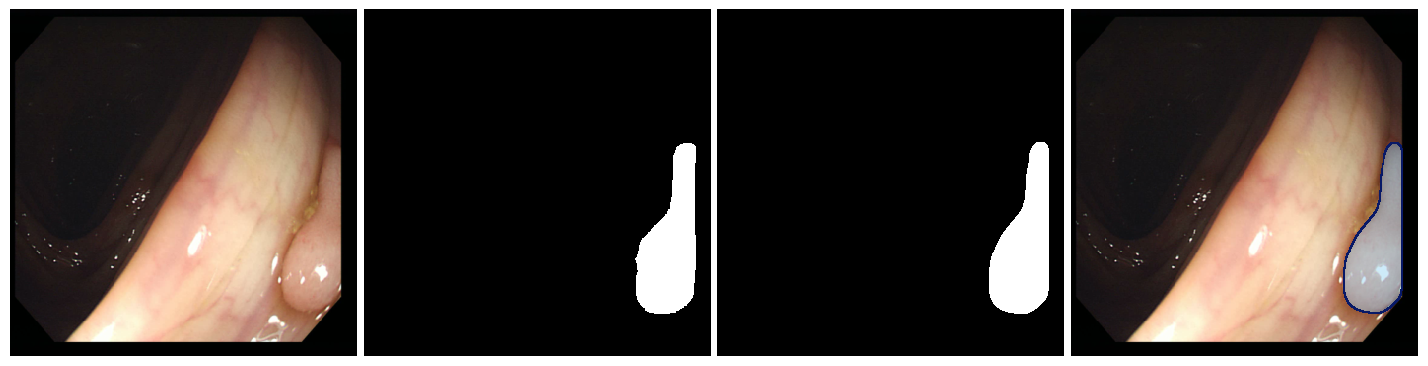

Prediction and export completed.
Prediction foreground pixels: 6913
Ground-truth foreground pixels: 6968
Output directory: /kaggle/working/segmentation_results
Download archive: /kaggle/working/segmentation_results.zip


In [17]:

import os
import zipfile
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.ndimage import binary_erosion, binary_dilation
import torchvision.transforms as T

IMAGE_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/images/100.png"
MASK_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/masks/100.png"
CHECKPOINT_PATH = "/kaggle/working/best_model.pth"
OUTPUT_DIR = "/kaggle/working/segmentation_results"

IMAGE_SIZE = (352, 352)
THRESHOLD = 0.5
FILL_COLOR = np.array([135, 206, 250], dtype=np.float32)
FILL_ALPHA = 0.4
BORDER_COLOR = np.array([8, 25, 103], dtype=np.uint8)
BORDER_WIDTH = 2

os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=True
)
model.load_state_dict(checkpoint)
model.eval()

image_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image = ImageOps.exif_transpose(
    Image.open(IMAGE_PATH)
).convert("RGB")

image_352 = image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.BILINEAR
)
original = np.asarray(image_352).copy()
input_tensor = image_transform(image).unsqueeze(0).to(device)

gt_image = ImageOps.exif_transpose(
    Image.open(MASK_PATH)
).convert("L")

gt_image = gt_image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.NEAREST
)
gt_mask = (np.asarray(gt_image) > 127).astype(np.uint8)

with torch.inference_mode():
    logits = model(input_tensor)
    logits = F.interpolate(
        logits,
        size=IMAGE_SIZE,
        mode="bilinear",
        align_corners=False
    )
    probabilities = torch.sigmoid(logits)[0, 0].cpu().numpy()
    pred_mask = (probabilities >= THRESHOLD).astype(np.uint8)

overlay = original.astype(np.float32).copy()
foreground = pred_mask.astype(bool)

overlay[foreground] = (
    (1.0 - FILL_ALPHA) * overlay[foreground]
    + FILL_ALPHA * FILL_COLOR
)

boundary = foreground & ~binary_erosion(
    foreground,
    structure=np.ones((3, 3), dtype=bool),
    iterations=1,
    border_value=0
)

if BORDER_WIDTH > 1:
    boundary = binary_dilation(
        boundary,
        structure=np.ones((3, 3), dtype=bool),
        iterations=BORDER_WIDTH - 1
    ) & foreground

overlay[boundary] = BORDER_COLOR
overlay = np.clip(overlay, 0, 255).astype(np.uint8)

Image.fromarray(pred_mask * 255).save(
    os.path.join(OUTPUT_DIR, "predicted_mask.png")
)
Image.fromarray(gt_mask * 255).save(
    os.path.join(OUTPUT_DIR, "ground_truth_mask.png")
)
Image.fromarray(overlay).save(
    os.path.join(OUTPUT_DIR, "prediction_overlay.png")
)

panels = [original, gt_mask * 255, pred_mask * 255, overlay]
names = [
    "original",
    "ground_truth",
    "predicted_mask",
    "prediction_overlay"
]

fig, axes = plt.subplots(1, 4, figsize=(14.08, 3.52))

for ax, panel in zip(axes, panels):
    if panel.ndim == 2:
        ax.imshow(
            panel, cmap="gray", vmin=0, vmax=255,
            interpolation="nearest", origin="upper"
        )
    else:
        ax.imshow(panel, interpolation="nearest", origin="upper")
    ax.axis("off")

fig.subplots_adjust(
    left=0, right=1, top=1, bottom=0, wspace=0.02
)

fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.png"),
    dpi=300, bbox_inches="tight", pad_inches=0
)
fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.pdf"),
    dpi=300, bbox_inches="tight", pad_inches=0
)
plt.show()
plt.close(fig)

for name, panel in zip(names, panels):
    fig_one, ax = plt.subplots(figsize=(3.52, 3.52))

    if panel.ndim == 2:
        ax.imshow(
            panel, cmap="gray", vmin=0, vmax=255,
            interpolation="nearest", origin="upper"
        )
    else:
        ax.imshow(panel, interpolation="nearest", origin="upper")

    ax.axis("off")
    fig_one.subplots_adjust(left=0, right=1, top=1, bottom=0)

    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.png"),
        dpi=300, bbox_inches="tight", pad_inches=0
    )
    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.pdf"),
        dpi=300, bbox_inches="tight", pad_inches=0
    )
    plt.close(fig_one)

zip_path = "/kaggle/working/segmentation_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in sorted(os.listdir(OUTPUT_DIR)):
        archive.write(
            os.path.join(OUTPUT_DIR, filename),
            arcname=filename
        )

print("Prediction and export completed.")
print(f"Prediction foreground pixels: {pred_mask.sum()}")
print(f"Ground-truth foreground pixels: {gt_mask.sum()}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Download archive: {zip_path}")

# TransUNet

In [11]:
import os
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

VIT_R50_URL = 'https://storage.googleapis.com/vit_models/imagenet21k/R50+ViT-B_16.npz'


def _t(a, conv=False):
    a = np.asarray(a)
    if conv:
        a = a.transpose(3, 2, 0, 1)      # HWIO -> OIHW
    return torch.from_numpy(np.ascontiguousarray(a)).float()


def ConvBlock(in_channels, out_channels):
    # Official Conv2dReLU: conv -> BN -> ReLU
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


class StdConv2d(nn.Conv2d):
    def forward(self, x):
        w = self.weight
        v, m = torch.var_mean(w, dim=[1, 2, 3], keepdim=True, unbiased=False)
        w = (w - m) / torch.sqrt(v + 1e-5)
        return F.conv2d(x, w, self.bias, self.stride, self.padding,
                        self.dilation, self.groups)


def conv3x3(cin, cout, stride=1):
    return StdConv2d(cin, cout, 3, stride=stride, padding=1, bias=False)


def conv1x1(cin, cout, stride=1):
    return StdConv2d(cin, cout, 1, stride=stride, padding=0, bias=False)


class PreActBottleneck(nn.Module):
    def __init__(self, cin, cout=None, cmid=None, stride=1):
        super().__init__()
        cout = cout or cin
        cmid = cmid or cout // 4

        self.gn1 = nn.GroupNorm(32, cmid, eps=1e-6)
        self.conv1 = conv1x1(cin, cmid)
        self.gn2 = nn.GroupNorm(32, cmid, eps=1e-6)
        self.conv2 = conv3x3(cmid, cmid, stride)
        self.gn3 = nn.GroupNorm(32, cout, eps=1e-6)
        self.conv3 = conv1x1(cmid, cout)
        self.relu = nn.ReLU(inplace=True)

        self.downsample = None
        if stride != 1 or cin != cout:
            self.downsample = conv1x1(cin, cout, stride)
            self.gn_proj = nn.GroupNorm(cout, cout)

    def forward(self, x):
        residual = x
        if self.downsample is not None:
            residual = self.gn_proj(self.downsample(x))
        y = self.relu(self.gn1(self.conv1(x)))
        y = self.relu(self.gn2(self.conv2(y)))
        y = self.gn3(self.conv3(y))
        return self.relu(residual + y)


class ResNetV2Encoder(nn.Module):
    """R50 (BiT-style) with block units (3, 4, 9); output at 1/16 plus 3 skips."""
    def __init__(self, block_units=(3, 4, 9), width_factor=1):
        super().__init__()
        width = int(64 * width_factor)
        self.width = width

        self.root = nn.Sequential(
            StdConv2d(3, width, 7, stride=2, padding=3, bias=False),
            nn.GroupNorm(32, width, eps=1e-6),
            nn.ReLU(inplace=True)
        )
        self.pool = nn.MaxPool2d(kernel_size=3, stride=2, padding=0)

        self.body = nn.Sequential(
            nn.Sequential(
                PreActBottleneck(width, width * 4, width),
                *[PreActBottleneck(width * 4, width * 4, width) for _ in range(block_units[0] - 1)]
            ),
            nn.Sequential(
                PreActBottleneck(width * 4, width * 8, width * 2, stride=2),
                *[PreActBottleneck(width * 8, width * 8, width * 2) for _ in range(block_units[1] - 1)]
            ),
            nn.Sequential(
                PreActBottleneck(width * 8, width * 16, width * 4, stride=2),
                *[PreActBottleneck(width * 16, width * 16, width * 4) for _ in range(block_units[2] - 1)]
            ),
        )

    def forward(self, x):
        features = []
        b, _, in_size, _ = x.shape
        x = self.root(x)
        features.append(x)                                   # 1/2, 64 ch
        x = self.pool(x)                                     # padding=0, as in the official code
        for i, block in enumerate(self.body[:-1]):
            x = block(x)
            right_size = int(in_size / 4 / (i + 1))
            if x.shape[2] != right_size:
                feat = torch.zeros(b, x.shape[1], right_size, right_size, device=x.device)
                feat[:, :, :x.shape[2], :x.shape[3]] = x
            else:
                feat = x
            features.append(feat)                            # 1/4 (256 ch), 1/8 (512 ch)
        x = self.body[-1](x)                                 # 1/16, 1024 ch
        return x, features[::-1]                             # skips: [512, 256, 64]


class TransformerEncoder(nn.Module):
    """ViT-B/16 hybrid: patch embedding (1x1 conv) + learned pos-emb + 12 pre-norm layers."""
    def __init__(self, in_channels=1024, embed_dim=768, depth=12, heads=12,
                 mlp_dim=3072, dropout=0.1, img_size=224):
        super().__init__()
        self.grid = img_size // 16
        self.proj = nn.Conv2d(in_channels, embed_dim, 1)
        self.pos_embed = nn.Parameter(torch.zeros(1, self.grid * self.grid, embed_dim))
        self.drop = nn.Dropout(dropout)

        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True,
            layer_norm_eps=1e-6
        )
        self.transformer = nn.TransformerEncoder(layer, num_layers=depth)
        self.norm = nn.LayerNorm(embed_dim, eps=1e-6)

    def forward(self, x):
        x = self.proj(x)
        b, c, h, w = x.shape
        tokens = x.flatten(2).transpose(1, 2)
        pos = self.pos_embed
        if tokens.shape[1] != pos.shape[1]:   # interpolate if input size differs
            g = int(math.sqrt(pos.shape[1]))
            pos = pos.reshape(1, g, g, -1).permute(0, 3, 1, 2)
            pos = F.interpolate(pos, size=(h, w), mode='bilinear', align_corners=False)
            pos = pos.flatten(2).transpose(1, 2)
        tokens = self.drop(tokens + pos)
        tokens = self.norm(self.transformer(tokens))
        return tokens.transpose(1, 2).reshape(b, c, h, w)


class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.UpsamplingBilinear2d(scale_factor=2)
        self.conv1 = ConvBlock(in_channels + skip_channels, out_channels)
        self.conv2 = ConvBlock(out_channels, out_channels)

    def forward(self, x, skip=None):
        x = self.up(x)
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv2(self.conv1(x))


class TransUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, img_size=352, pretrained=True,
                 pretrained_path=None, pretrained_url=VIT_R50_URL,
                 embed_dim=768, transformer_depth=12, num_heads=12):
        super().__init__()
        if img_size % 16 != 0:
            raise ValueError("img_size must be divisible by 16.")
        if pretrained and (embed_dim, transformer_depth, num_heads) != (768, 12, 12):
            raise ValueError("The pretrained weights need embed_dim=768, depth=12, heads=12.")

        self.encoder = ResNetV2Encoder(block_units=(3, 4, 9), width_factor=1)
        self.transformer = TransformerEncoder(
            in_channels=1024,
            embed_dim=embed_dim,
            depth=transformer_depth,
            heads=num_heads,
            mlp_dim=embed_dim * 4,
            img_size=img_size
        )

        self.proj = ConvBlock(embed_dim, 512)   # official "conv_more"

        # in: 512 -> 256 -> 128 -> 64 ; out: 256, 128, 64, 16 ; skips: 512, 256, 64, 0
        self.decoder4 = DecoderBlock(512, 512, 256)
        self.decoder3 = DecoderBlock(256, 256, 128)
        self.decoder2 = DecoderBlock(128, 64, 64)
        self.decoder1 = DecoderBlock(64, 0, 16)

        self.final = nn.Conv2d(16, out_channels, 3, padding=1)

        if pretrained:
            path = pretrained_path
            if path is None:
                ckpt_dir = os.path.join(torch.hub.get_dir(), 'checkpoints')
                os.makedirs(ckpt_dir, exist_ok=True)
                path = os.path.join(ckpt_dir, 'R50+ViT-B_16.npz')
                if not os.path.exists(path):
                    torch.hub.download_url_to_file(pretrained_url, path)   # raises on failure
            self.load_from(np.load(path))
        else:
            print("TransUNet: no pretrained weights, training from scratch.")

    @torch.no_grad()
    def load_from(self, w):
        """Load Google's R50+ViT-B_16.npz into the ResNetV2 encoder and the ViT.
        Decoder, conv_more and the segmentation head stay random, as in the official model."""
        count = 0

        def cp(param, value):
            nonlocal count
            if param.shape != value.shape:
                raise RuntimeError(f"Shape mismatch: model {tuple(param.shape)} vs weights {tuple(value.shape)}")
            param.copy_(value)
            count += 1

        # --- ResNetV2 root ---
        cp(self.encoder.root[0].weight, _t(w['conv_root/kernel'], conv=True))
        cp(self.encoder.root[1].weight, _t(w['gn_root/scale']).reshape(-1))
        cp(self.encoder.root[1].bias, _t(w['gn_root/bias']).reshape(-1))

        # --- ResNetV2 body: body[b][u] <-> block{b+1}/unit{u+1} ---
        for bi, block in enumerate(self.encoder.body):
            for ui, unit in enumerate(block):
                p = f'block{bi + 1}/unit{ui + 1}/'
                for k in (1, 2, 3):
                    cp(getattr(unit, f'conv{k}').weight, _t(w[p + f'conv{k}/kernel'], conv=True))
                    cp(getattr(unit, f'gn{k}').weight, _t(w[p + f'gn{k}/scale']).reshape(-1))
                    cp(getattr(unit, f'gn{k}').bias, _t(w[p + f'gn{k}/bias']).reshape(-1))
                if unit.downsample is not None:
                    cp(unit.downsample.weight, _t(w[p + 'conv_proj/kernel'], conv=True))
                    cp(unit.gn_proj.weight, _t(w[p + 'gn_proj/scale']).reshape(-1))
                    cp(unit.gn_proj.bias, _t(w[p + 'gn_proj/bias']).reshape(-1))

        # --- ViT: patch embedding, final norm, positional embedding ---
        tr = self.transformer
        H = tr.proj.out_channels
        cp(tr.proj.weight, _t(w['embedding/kernel'], conv=True))
        cp(tr.proj.bias, _t(w['embedding/bias']).reshape(-1))
        cp(tr.norm.weight, _t(w['Transformer/encoder_norm/scale']).reshape(-1))
        cp(tr.norm.bias, _t(w['Transformer/encoder_norm/bias']).reshape(-1))

        pe = _t(w['Transformer/posembed_input/pos_embedding'])          # (1, N, 768)
        if math.isqrt(pe.shape[1]) ** 2 != pe.shape[1]:                  # drop class token if present
            pe = pe[:, 1:]
        g_old, g_new = math.isqrt(pe.shape[1]), tr.grid
        if g_old != g_new:                                               # 14x14 -> 22x22 for 352
            grid = pe.reshape(1, g_old, g_old, -1).permute(0, 3, 1, 2)
            grid = F.interpolate(grid, size=(g_new, g_new), mode='bilinear', align_corners=False)
            pe = grid.permute(0, 2, 3, 1).reshape(1, g_new * g_new, -1)
        cp(tr.pos_embed, pe)

        # --- ViT encoder blocks ---
        for i, layer in enumerate(tr.transformer.layers):
            r = f'Transformer/encoderblock_{i}/'
            a = r + 'MultiHeadDotProductAttention_1/'
            q, k, v = [_t(w[a + n + '/kernel']).reshape(H, H).t() for n in ('query', 'key', 'value')]
            qb, kb, vb = [_t(w[a + n + '/bias']).reshape(-1) for n in ('query', 'key', 'value')]
            cp(layer.self_attn.in_proj_weight, torch.cat([q, k, v], dim=0))
            cp(layer.self_attn.in_proj_bias, torch.cat([qb, kb, vb], dim=0))
            cp(layer.self_attn.out_proj.weight, _t(w[a + 'out/kernel']).reshape(H, H).t())
            cp(layer.self_attn.out_proj.bias, _t(w[a + 'out/bias']).reshape(-1))
            cp(layer.linear1.weight, _t(w[r + 'MlpBlock_3/Dense_0/kernel']).t())
            cp(layer.linear1.bias, _t(w[r + 'MlpBlock_3/Dense_0/bias']).reshape(-1))
            cp(layer.linear2.weight, _t(w[r + 'MlpBlock_3/Dense_1/kernel']).t())
            cp(layer.linear2.bias, _t(w[r + 'MlpBlock_3/Dense_1/bias']).reshape(-1))
            cp(layer.norm1.weight, _t(w[r + 'LayerNorm_0/scale']).reshape(-1))
            cp(layer.norm1.bias, _t(w[r + 'LayerNorm_0/bias']).reshape(-1))
            cp(layer.norm2.weight, _t(w[r + 'LayerNorm_2/scale']).reshape(-1))
            cp(layer.norm2.bias, _t(w[r + 'LayerNorm_2/bias']).reshape(-1))

        print(f"TransUNet: R50+ViT-B_16 weights loaded ({count} tensors)")

    def forward(self, x):
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)
        x, skips = self.encoder(x)          # skips: [1/8 (512), 1/4 (256), 1/2 (64)]
        x = self.transformer(x)
        x = self.proj(x)
        x = self.decoder4(x, skips[0])
        x = self.decoder3(x, skips[1])
        x = self.decoder2(x, skips[2])
        x = self.decoder1(x, None)
        return self.final(x)

    def param_groups(self, lr_enc=1e-4, lr_dec=3e-4):
        enc = list(self.encoder.parameters())
        dec = (
            list(self.transformer.parameters()) +
            list(self.proj.parameters()) +
            list(self.decoder4.parameters()) +
            list(self.decoder3.parameters()) +
            list(self.decoder2.parameters()) +
            list(self.decoder1.parameters()) +
            list(self.final.parameters())
        )
        return [
            {'params': enc, 'lr': lr_enc},
            {'params': dec, 'lr': lr_dec}
        ]


model = TransUNet(
    in_channels=3,
    out_channels=1,
    img_size=352,
    pretrained=True          # downloads Google's R50+ViT-B_16.npz on first run
).to(device)

with torch.no_grad():
    y = model(torch.randn(2, 3, 352, 352, device=device))
print(y.shape)   # expect torch.Size([2, 1, 352, 352])

/tmp/ipykernel_49/1724118777.py:141: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=depth)
100%|██████████| 440M/440M [00:12<00:00, 36.8MB/s] 


TransUNet: R50+ViT-B_16 weights loaded (305 tensors)
torch.Size([2, 1, 352, 352])


In [12]:
import time
import pandas as pd
import torch


def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)


@torch.no_grad()
def latency(m, x, warmup=20, runs=50):
    m.eval()
    for _ in range(warmup):
        _ = m(x)
    if x.is_cuda:
        torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(runs):
        _ = m(x)
    if x.is_cuda:
        torch.cuda.synchronize()
    ms = (time.perf_counter() - t) / runs * 1000
    return ms, 1000 / ms


def flops(m, x):
    acts = [torch.profiler.ProfilerActivity.CPU]
    if x.is_cuda:
        acts.append(torch.profiler.ProfilerActivity.CUDA)
    m.eval()
    with torch.no_grad():
        with torch.profiler.profile(activities=acts, with_flops=True) as p:
            _ = m(x)
    return sum(getattr(e, "flops", 0) or 0 for e in p.key_averages()) / 1e9


def efficiency(name, m, x):
    n, tr = count_params(m)
    g = flops(m, x)
    ms, fps = latency(m, x)
    mem = None

    if x.is_cuda:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        with torch.no_grad():
            _ = m(x)
        torch.cuda.synchronize()
        mem = torch.cuda.max_memory_allocated() / 1024**2

    r = {
        "Model": name,
        "Params(M)": n / 1e6,
        "Trainable(M)": tr / 1e6,
        "GFLOPs": g,
        "Latency(ms)": ms,
        "FPS": fps,
        "GPU(MB)": mem
    }

    msg = (
        f"{name}: Params={n/1e6:.3f}M | GFLOPs={g:.3f} | "
        f"Latency={ms:.2f}ms | FPS={fps:.2f}"
    )
    if mem is not None:
        msg += f" | GPU={mem:.1f}MB"
    print(msg)
    return r


model = TransUNet(
    in_channels=3,
    out_channels=1,
    img_size=352,    
    pretrained=True,
    embed_dim=768,
    transformer_depth=12,
    num_heads=12
).to(device)

model.eval()
dummy = torch.randn(1, 3, 352, 352, device=device)

r1 = efficiency("TransUNet", model, dummy)

print("\nParameter breakdown:")
for name, module in [
    ("CNN Encoder", model.encoder),
    ("Transformer", model.transformer),
    ("Projection", model.proj),
    ("Decoder 4", model.decoder4),
    ("Decoder 3", model.decoder3),
    ("Decoder 2", model.decoder2),
    ("Decoder 1", model.decoder1),
    ("Final Layer", model.final),
    ("Full Model", model)
]:
    p, t = count_params(module)
    print(f"{name:<16}: {p/1e6:.3f}M total | {t/1e6:.3f}M trainable")

efficiency_df = pd.DataFrame([r1])
print("\n", efficiency_df.to_string(index=False))

/tmp/ipykernel_49/1724118777.py:141: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(layer, num_layers=depth)


TransUNet: R50+ViT-B_16 weights loaded (305 tensors)


/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


TransUNet: Params=105.497M | GFLOPs=113.215 | Latency=49.78ms | FPS=20.09 | GPU=497.8MB

Parameter breakdown:
CNN Encoder     : 11.895M total | 11.895M trainable
Transformer     : 86.215M total | 86.215M trainable
Projection      : 3.540M total | 3.540M trainable
Decoder 4       : 2.950M total | 2.950M trainable
Decoder 3       : 0.738M total | 0.738M trainable
Decoder 2       : 0.148M total | 0.148M trainable
Decoder 1       : 0.012M total | 0.012M trainable
Final Layer     : 0.000M total | 0.000M trainable
Full Model      : 105.497M total | 105.497M trainable

     Model  Params(M)  Trainable(M)     GFLOPs  Latency(ms)       FPS    GPU(MB)
TransUNet 105.497105    105.497105 113.214537    49.780188 20.088313 497.835938


In [13]:
import random, math, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


class StructureDiceLoss(nn.Module):
    def __init__(self, dice_w=0.5):
        super().__init__()
        self.dice_w = dice_w

    def forward(self, logits, targets):
        t = targets.unsqueeze(1).float()
        weit = 1 + 5 * torch.abs(F.avg_pool2d(t, 31, 1, 15) - t)
        wbce = (F.binary_cross_entropy_with_logits(logits, t, reduction='none') * weit).sum((2, 3)) / weit.sum((2, 3))
        p = torch.sigmoid(logits)
        inter = (p * t * weit).sum((2, 3))
        union = ((p + t) * weit).sum((2, 3))
        wiou = 1 - (inter + 1) / (union - inter + 1)
        inter_d = (p * t).sum((2, 3))
        den = p.sum((2, 3)) + t.sum((2, 3))
        dice = 1 - (2 * inter_d + 1e-6) / (den + 1e-6)
        return (wbce + wiou).mean() + self.dice_w * dice.mean()


criterion = StructureDiceLoss().to(device)

num_epochs = 150
optimizer = torch.optim.AdamW(
    model.param_groups(lr_enc=1e-4, lr_dec=3e-4),
    weight_decay=1e-4
)

warmup_epochs = 5

def lr_lambda(ep):
    if ep < warmup_epochs:
        return (ep + 1) / warmup_epochs
    prog = (ep - warmup_epochs) / max(1, num_epochs - warmup_epochs)
    return max(0.01, 0.5 * (1 + math.cos(math.pi * prog)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

ema = copy.deepcopy(model).to(device)
ema.eval()

for p in ema.parameters():
    p.requires_grad_(False)

ema_decay = 0.995

@torch.no_grad()
def ema_update(ema_m, src, decay):
    for pe, ps in zip(ema_m.parameters(), src.parameters()):
        pe.mul_(decay).add_(ps.detach(), alpha=1 - decay)
    for be, bs in zip(ema_m.buffers(), src.buffers()):
        be.copy_(bs)


@torch.no_grad()
def evaluate(m, loader):
    m.eval()
    n = 0
    vl = vd = vi = 0.0

    for imgs, masks, _ in loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = m(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(preds, size=masks.shape[-2:], mode='bilinear', align_corners=False)

        b = imgs.size(0)
        vl += criterion(preds, masks).item() * b
        vd += dice_score(preds, masks).item() * b
        vi += iou_score(preds, masks).item() * b
        n += b

    return vl / n, vd / n, vi / n


class EarlyStopping:
    def __init__(self, patience=40, min_epochs=40, verbose=True):
        self.patience, self.min_epochs, self.verbose = patience, min_epochs, verbose
        self.counter, self.best, self.stop = 0, None, False

    def __call__(self, score, model_to_save, epoch):
        if self.best is None or score > self.best + 1e-4:
            self.best, self.counter = score, 0
            torch.save(model_to_save.state_dict(), "best_model.pth")
            if self.verbose:
                print(f"Val Dice improved to {self.best:.4f} - EMA model saved.")
        else:
            self.counter += 1
            if self.verbose:
                print(f"No improvement. EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience and (epoch + 1) >= self.min_epochs:
                print("Early stopping triggered.")
                self.stop = True


early_stopping = EarlyStopping(patience=40, min_epochs=40, verbose=True)

train_losses, val_losses = [], []
train_dices, val_dices = [], []
train_ious, val_ious = [], []

global_step = 0

for epoch in range(num_epochs):
    model.train()
    train_loss = train_dice = train_iou = 0.0

    for imgs, masks, labels in train_loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = model(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(preds, size=masks.shape[-2:], mode='bilinear', align_corners=False)

        loss = criterion(preds, masks)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        global_step += 1
        ema_update(ema, model, min(ema_decay, (1 + global_step) / (10 + global_step)))

        train_loss += loss.item()
        train_dice += dice_score(preds.detach(), masks).item()
        train_iou += iou_score(preds.detach(), masks).item()

    val_loss, val_dice, val_iou = evaluate(ema, val_loader)

    avg_train_loss = train_loss / len(train_loader)
    avg_train_dice = train_dice / len(train_loader)
    avg_train_iou = train_iou / len(train_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(val_loss)
    train_dices.append(avg_train_dice)
    val_dices.append(val_dice)
    train_ious.append(avg_train_iou)
    val_ious.append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train Dice: {avg_train_dice:.4f} | Val Dice: {val_dice:.4f} | "
        f"Train IoU: {avg_train_iou:.4f} | Val IoU: {val_iou:.4f} | "
        f"LR(enc): {optimizer.param_groups[0]['lr']:.2e}"
    )

    scheduler.step()
    early_stopping(val_dice, ema, epoch)

    if early_stopping.stop:
        print(f"\nTraining stopped early at epoch {epoch+1}.")
        break

model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()
print(f"\nBest EMA model loaded (best val Dice {early_stopping.best:.4f}).")

Epoch [1/150] Train Loss: 1.8209 | Val Loss: 1.8163 | Train Dice: 0.2205 | Val Dice: 0.1848 | Train IoU: 0.1425 | Val IoU: 0.1087 | LR(enc): 2.00e-05
Val Dice improved to 0.1848 - EMA model saved.
Epoch [2/150] Train Loss: 1.6008 | Val Loss: 1.6310 | Train Dice: 0.6150 | Val Dice: 0.6816 | Train IoU: 0.4916 | Val IoU: 0.5535 | LR(enc): 4.00e-05
Val Dice improved to 0.6816 - EMA model saved.
Epoch [3/150] Train Loss: 1.4711 | Val Loss: 1.5284 | Train Dice: 0.7793 | Val Dice: 0.7811 | Train IoU: 0.6782 | Val IoU: 0.6739 | LR(enc): 6.00e-05
Val Dice improved to 0.7811 - EMA model saved.
Epoch [4/150] Train Loss: 1.3362 | Val Loss: 1.3721 | Train Dice: 0.8148 | Val Dice: 0.8280 | Train IoU: 0.7236 | Val IoU: 0.7344 | LR(enc): 8.00e-05
Val Dice improved to 0.8280 - EMA model saved.
Epoch [5/150] Train Loss: 1.1810 | Val Loss: 1.2134 | Train Dice: 0.8334 | Val Dice: 0.8555 | Train IoU: 0.7396 | Val IoU: 0.7733 | LR(enc): 1.00e-04
Val Dice improved to 0.8555 - EMA model saved.
Epoch [6/150] T

In [14]:
import numpy as np
import torch
import torch.nn.functional as F
from scipy import ndimage


def _get_boundary(mask):
    mask = mask.astype(bool)
    if not mask.any():
        return np.zeros_like(mask, dtype=bool)
    eroded = ndimage.binary_erosion(mask, structure=np.ones((3, 3)))
    return mask ^ eroded


def _surface_distances(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    pred_surface, gt_surface = _get_boundary(pred), _get_boundary(gt)

    if not pred.any() and not gt.any():
        return np.array([0.0]), np.array([0.0])
    if not pred.any() or not gt.any():
        h, w = pred.shape
        max_dist = np.sqrt(h**2 + w**2)
        return np.array([max_dist]), np.array([max_dist])

    dt_gt = ndimage.distance_transform_edt(~gt_surface)
    dt_pred = ndimage.distance_transform_edt(~pred_surface)
    return dt_gt[pred_surface], dt_pred[gt_surface]


def _assd(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return (np.mean(d1) + np.mean(d2)) / 2.0


def _hd95(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return np.percentile(np.concatenate([d1, d2]), 95)


def _bf1(pred, gt, tolerance=2):
    pred_boundary, gt_boundary = _get_boundary(pred), _get_boundary(gt)
    pred_count, gt_count = pred_boundary.sum(), gt_boundary.sum()

    if pred_count == 0 and gt_count == 0:
        return 1.0
    if pred_count == 0 or gt_count == 0:
        return 0.0

    dt_gt = ndimage.distance_transform_edt(~gt_boundary)
    dt_pred = ndimage.distance_transform_edt(~pred_boundary)
    precision = (dt_gt[pred_boundary] <= tolerance).sum() / (pred_count + 1e-6)
    recall = (dt_pred[gt_boundary] <= tolerance).sum() / (gt_count + 1e-6)
    return 2 * precision * recall / (precision + recall + 1e-6)


def evaluate_segmentation(model, test_loader, device, thr=0.4, seed=42):
    model.eval()
    model.to(device)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    rows = []

    with torch.no_grad():
        for imgs, masks, labels in test_loader:
            imgs = imgs.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.long)
            outputs = model(imgs)

            if outputs.shape[-2:] != masks.shape[-2:]:
                outputs = F.interpolate(
                    outputs, size=masks.shape[-2:],
                    mode='bilinear', align_corners=False
                )

            preds = (torch.sigmoid(outputs) > thr).squeeze(1)
            gts = masks.bool()

            for b in range(preds.shape[0]):
                p, g = preds[b], gts[b]
                tp = (p & g).sum().item()
                fp = (p & ~g).sum().item()
                fn = (~p & g).sum().item()
                e = 1e-6

                pn = p.cpu().numpy()
                gn = g.cpu().numpy()

                rows.append({
                    "dice": (2 * tp + e) / (2 * tp + fp + fn + e),
                    "iou": (tp + e) / (tp + fp + fn + e),
                    "prec": (tp + e) / (tp + fp + e),
                    "rec": (tp + e) / (tp + fn + e),
                    "bf1": _bf1(pn, gn, tolerance=2),
                    "assd": _assd(pn, gn),
                    "hd95": _hd95(pn, gn)
                })

    if not rows:
        raise ValueError("The test_loader is empty.")

    M = {k: np.array([r[k] for r in rows]) for k in rows[0]}

    print("\n============ Test Set (per-image, polyp class) ============")
    print(f"  Dice      : {M['dice'].mean():.4f}")
    print(f"  IoU       : {M['iou'].mean():.4f}")
    print(f"  Precision : {M['prec'].mean():.4f}")
    print(f"  Recall    : {M['rec'].mean():.4f}")
    print(f"  BF1       : {M['bf1'].mean():.4f}")
    print(f"  ASSD      : {M['assd'].mean():.4f} px")
    print(f"  HD95      : {M['hd95'].mean():.4f} px")
    print("===========================================================\n")

    return {**{k: float(v.mean()) for k, v in M.items()}, "per_image": M}


results = evaluate_segmentation(model, test_loader, device=device, thr=0.4)


============ Test Set (per-image, polyp class) ============
  Dice      : 0.9090
  IoU       : 0.8516
  Precision : 0.8996
  Recall    : 0.9425
  BF1       : 0.6708
  ASSD      : 3.5244 px
  HD95      : 11.4297 px



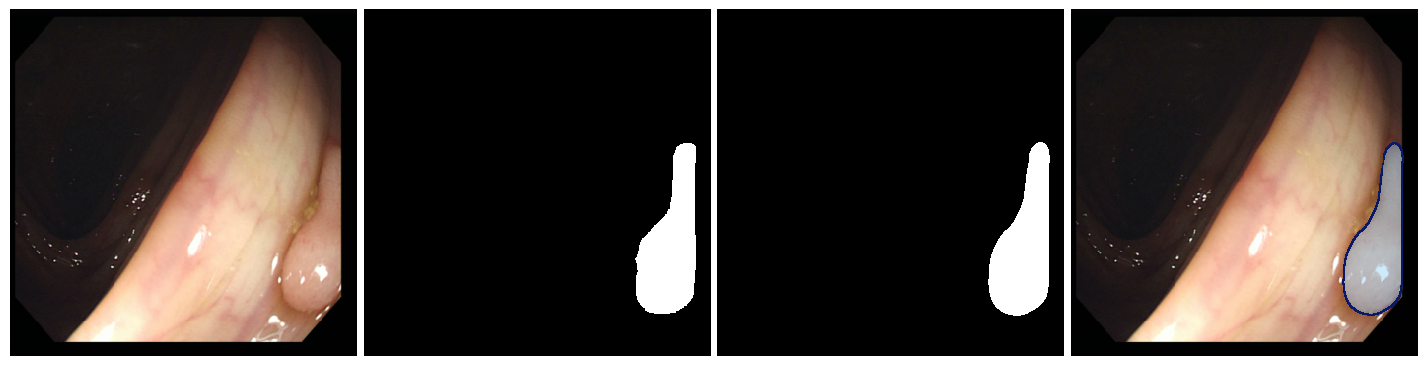

Prediction and export completed.
Prediction foreground pixels: 6989
Ground-truth foreground pixels: 6968
Output directory: /kaggle/working/segmentation_results
Download archive: /kaggle/working/segmentation_results.zip


In [15]:

import os
import zipfile
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.ndimage import binary_erosion, binary_dilation
import torchvision.transforms as T

IMAGE_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/images/100.png"
MASK_PATH = "/kaggle/input/datasets/longvil/cvc-colondb/CVC-ColonDB/masks/100.png"
CHECKPOINT_PATH = "/kaggle/working/best_model.pth"
OUTPUT_DIR = "/kaggle/working/segmentation_results"

IMAGE_SIZE = (352, 352)
THRESHOLD = 0.5
FILL_COLOR = np.array([135, 206, 250], dtype=np.float32)
FILL_ALPHA = 0.4
BORDER_COLOR = np.array([8, 25, 103], dtype=np.uint8)
BORDER_WIDTH = 2

os.makedirs(OUTPUT_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=True
)
model.load_state_dict(checkpoint)
model.eval()

image_transform = T.Compose([
    T.Resize(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image = ImageOps.exif_transpose(
    Image.open(IMAGE_PATH)
).convert("RGB")

image_352 = image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.BILINEAR
)
original = np.asarray(image_352).copy()
input_tensor = image_transform(image).unsqueeze(0).to(device)

gt_image = ImageOps.exif_transpose(
    Image.open(MASK_PATH)
).convert("L")

gt_image = gt_image.resize(
    (IMAGE_SIZE[1], IMAGE_SIZE[0]),
    Image.Resampling.NEAREST
)
gt_mask = (np.asarray(gt_image) > 127).astype(np.uint8)

with torch.inference_mode():
    logits = model(input_tensor)
    logits = F.interpolate(
        logits,
        size=IMAGE_SIZE,
        mode="bilinear",
        align_corners=False
    )
    probabilities = torch.sigmoid(logits)[0, 0].cpu().numpy()
    pred_mask = (probabilities >= THRESHOLD).astype(np.uint8)

overlay = original.astype(np.float32).copy()
foreground = pred_mask.astype(bool)

overlay[foreground] = (
    (1.0 - FILL_ALPHA) * overlay[foreground]
    + FILL_ALPHA * FILL_COLOR
)

boundary = foreground & ~binary_erosion(
    foreground,
    structure=np.ones((3, 3), dtype=bool),
    iterations=1,
    border_value=0
)

if BORDER_WIDTH > 1:
    boundary = binary_dilation(
        boundary,
        structure=np.ones((3, 3), dtype=bool),
        iterations=BORDER_WIDTH - 1
    ) & foreground

overlay[boundary] = BORDER_COLOR
overlay = np.clip(overlay, 0, 255).astype(np.uint8)

Image.fromarray(pred_mask * 255).save(
    os.path.join(OUTPUT_DIR, "predicted_mask.png")
)
Image.fromarray(gt_mask * 255).save(
    os.path.join(OUTPUT_DIR, "ground_truth_mask.png")
)
Image.fromarray(overlay).save(
    os.path.join(OUTPUT_DIR, "prediction_overlay.png")
)

panels = [original, gt_mask * 255, pred_mask * 255, overlay]
names = [
    "original",
    "ground_truth",
    "predicted_mask",
    "prediction_overlay"
]

fig, axes = plt.subplots(1, 4, figsize=(14.08, 3.52))

for ax, panel in zip(axes, panels):
    if panel.ndim == 2:
        ax.imshow(
            panel, cmap="gray", vmin=0, vmax=255,
            interpolation="nearest", origin="upper"
        )
    else:
        ax.imshow(panel, interpolation="nearest", origin="upper")
    ax.axis("off")

fig.subplots_adjust(
    left=0, right=1, top=1, bottom=0, wspace=0.02
)

fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.png"),
    dpi=300, bbox_inches="tight", pad_inches=0
)
fig.savefig(
    os.path.join(OUTPUT_DIR, "comparison.pdf"),
    dpi=300, bbox_inches="tight", pad_inches=0
)
plt.show()
plt.close(fig)

for name, panel in zip(names, panels):
    fig_one, ax = plt.subplots(figsize=(3.52, 3.52))

    if panel.ndim == 2:
        ax.imshow(
            panel, cmap="gray", vmin=0, vmax=255,
            interpolation="nearest", origin="upper"
        )
    else:
        ax.imshow(panel, interpolation="nearest", origin="upper")

    ax.axis("off")
    fig_one.subplots_adjust(left=0, right=1, top=1, bottom=0)

    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.png"),
        dpi=300, bbox_inches="tight", pad_inches=0
    )
    fig_one.savefig(
        os.path.join(OUTPUT_DIR, f"{name}.pdf"),
        dpi=300, bbox_inches="tight", pad_inches=0
    )
    plt.close(fig_one)

zip_path = "/kaggle/working/segmentation_results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in sorted(os.listdir(OUTPUT_DIR)):
        archive.write(
            os.path.join(OUTPUT_DIR, filename),
            arcname=filename
        )

print("Prediction and export completed.")
print(f"Prediction foreground pixels: {pred_mask.sum()}")
print(f"Ground-truth foreground pixels: {gt_mask.sum()}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"Download archive: {zip_path}")

# AttentionUNet

In [11]:

import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class AttentionGate(nn.Module):
    def __init__(self, gate_channels, skip_channels, inter_channels):
        super().__init__()

        self.W_g = nn.Sequential(
            nn.Conv2d(gate_channels, inter_channels, kernel_size=1, bias=True),
            nn.BatchNorm2d(inter_channels)
        )

        self.W_x = nn.Sequential(
            nn.Conv2d(skip_channels, inter_channels, kernel_size=1, bias=True),
            nn.BatchNorm2d(inter_channels)
        )

        self.psi = nn.Sequential(
            nn.Conv2d(inter_channels, 1, kernel_size=1, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)

        if g1.shape[2:] != x1.shape[2:]:
            g1 = F.interpolate(
                g1, size=x1.shape[2:],
                mode="bilinear", align_corners=False
            )

        attention = self.psi(self.relu(g1 + x1))
        return x * attention


class AttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.att4 = AttentionGate(512, 512, 256)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.att3 = AttentionGate(256, 256, 128)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.att2 = AttentionGate(128, 128, 64)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.att1 = AttentionGate(64, 64, 32)
        self.dec1 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        e4_att = self.att4(d4, e4)
        d4 = self.dec4(torch.cat([d4, e4_att], dim=1))

        d3 = self.up3(d4)
        e3_att = self.att3(d3, e3)
        d3 = self.dec3(torch.cat([d3, e3_att], dim=1))

        d2 = self.up2(d3)
        e2_att = self.att2(d2, e2)
        d2 = self.dec2(torch.cat([d2, e2_att], dim=1))

        d1 = self.up1(d2)
        e1_att = self.att1(d1, e1)
        d1 = self.dec1(torch.cat([d1, e1_att], dim=1))

        return self.final(d1)


if __name__ == "__main__":
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    model = AttentionUNet(
        in_channels=3,
        out_channels=1
    ).to(device)

    x = torch.randn(2, 3, 352, 352, device=device)

    model.eval()
    with torch.no_grad():
        y = model(x)

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    print("Output shape:", y.shape)
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")

Output shape: torch.Size([2, 1, 352, 352])
Total parameters: 31,389,165
Trainable parameters: 31,389,165


In [12]:

import time
import pandas as pd
import torch


def count_params(m):
    return (
        sum(p.numel() for p in m.parameters()),
        sum(p.numel() for p in m.parameters() if p.requires_grad)
    )


@torch.no_grad()
def latency(m, x, warmup=20, runs=50):
    m.eval()

    for _ in range(warmup):
        _ = m(x)

    if x.is_cuda:
        torch.cuda.synchronize()

    t = time.perf_counter()

    for _ in range(runs):
        _ = m(x)

    if x.is_cuda:
        torch.cuda.synchronize()

    ms = (time.perf_counter() - t) / runs * 1000
    return ms, 1000 / ms


def flops(m, x):
    acts = [torch.profiler.ProfilerActivity.CPU]

    if x.is_cuda:
        acts.append(torch.profiler.ProfilerActivity.CUDA)

    m.eval()

    with torch.no_grad():
        with torch.profiler.profile(
            activities=acts,
            with_flops=True
        ) as p:
            _ = m(x)

    return sum(
        getattr(e, "flops", 0) or 0
        for e in p.key_averages()
    ) / 1e9


def efficiency(name, m, x):
    n, tr = count_params(m)
    g = flops(m, x)
    ms, fps = latency(m, x)

    mem = None

    if x.is_cuda:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

        with torch.no_grad():
            _ = m(x)

        torch.cuda.synchronize()
        mem = torch.cuda.max_memory_allocated() / 1024**2

    r = {
        "Model": name,
        "Params(M)": n / 1e6,
        "Trainable(M)": tr / 1e6,
        "GFLOPs": g,
        "Latency(ms)": ms,
        "FPS": fps,
        "GPU(MB)": mem
    }

    msg = (
        f"{name}: Params={n/1e6:.3f}M | "
        f"Trainable={tr/1e6:.3f}M | "
        f"GFLOPs={g:.3f} | "
        f"Latency={ms:.2f}ms | FPS={fps:.2f}"
    )

    if mem is not None:
        msg += f" | GPU={mem:.1f}MB"

    print(msg)
    return r


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AttentionUNet(
    in_channels=3,
    out_channels=1
).to(device)

model.eval()

dummy = torch.randn(
    1, 3, 352, 352,
    device=device
)

r1 = efficiency("Attention U-Net", model, dummy)


print("\nParameter breakdown:")

for name, module in [
    ("Encoder 1", model.enc1),
    ("Encoder 2", model.enc2),
    ("Encoder 3", model.enc3),
    ("Encoder 4", model.enc4),
    ("Bottleneck", model.bottleneck),
    ("Attention Gate 4", model.att4),
    ("Attention Gate 3", model.att3),
    ("Attention Gate 2", model.att2),
    ("Attention Gate 1", model.att1),
    ("Decoder 4", model.dec4),
    ("Decoder 3", model.dec3),
    ("Decoder 2", model.dec2),
    ("Decoder 1", model.dec1),
    ("Final Conv", model.final),
    ("Full Model", model)
]:
    p, t = count_params(module)

    print(
        f"{name:<20}: "
        f"{p/1e6:.3f}M total | "
        f"{t/1e6:.3f}M trainable"
    )


efficiency_df = pd.DataFrame([r1])

print("\n", efficiency_df.to_string(index=False))

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


Attention U-Net: Params=31.389M | Trainable=31.389M | GFLOPs=178.110 | Latency=44.50ms | FPS=22.47 | GPU=419.9MB

Parameter breakdown:
Encoder 1           : 0.039M total | 0.039M trainable
Encoder 2           : 0.222M total | 0.222M trainable
Encoder 3           : 0.886M total | 0.886M trainable
Encoder 4           : 3.541M total | 3.541M trainable
Bottleneck          : 14.160M total | 14.160M trainable
Attention Gate 4    : 0.264M total | 0.264M trainable
Attention Gate 3    : 0.066M total | 0.066M trainable
Attention Gate 2    : 0.017M total | 0.017M trainable
Attention Gate 1    : 0.004M total | 0.004M trainable
Decoder 4           : 7.080M total | 7.080M trainable
Decoder 3           : 1.770M total | 1.770M trainable
Decoder 2           : 0.443M total | 0.443M trainable
Decoder 1           : 0.111M total | 0.111M trainable
Final Conv          : 0.000M total | 0.000M trainable
Full Model          : 31.389M total | 31.389M trainable

           Model  Params(M)  Trainable(M)     GFLO

In [13]:
import random
import math
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = AttentionUNet(in_channels=3, out_channels=1).to(device)


class StructureDiceLoss(nn.Module):
    def __init__(self, dice_w=0.5):
        super().__init__()
        self.dice_w = dice_w

    def forward(self, logits, targets):
        t = targets.unsqueeze(1).float()

        weit = 1 + 5 * torch.abs(
            F.avg_pool2d(t, 31, 1, 15) - t
        )

        wbce = (
            F.binary_cross_entropy_with_logits(
                logits, t, reduction="none"
            ) * weit
        ).sum((2, 3)) / weit.sum((2, 3))

        p = torch.sigmoid(logits)

        inter = (p * t * weit).sum((2, 3))
        union = ((p + t) * weit).sum((2, 3))
        wiou = 1 - (inter + 1) / (union - inter + 1)

        inter_d = (p * t).sum((2, 3))
        den = p.sum((2, 3)) + t.sum((2, 3))
        dice = 1 - (2 * inter_d + 1e-6) / (den + 1e-6)

        return (wbce + wiou).mean() + self.dice_w * dice.mean()


criterion = StructureDiceLoss().to(device)

num_epochs = 150

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

warmup_epochs = 5


def lr_lambda(ep):
    if ep < warmup_epochs:
        return (ep + 1) / warmup_epochs

    prog = (ep - warmup_epochs) / max(
        1, num_epochs - warmup_epochs
    )

    return max(
        0.01,
        0.5 * (1 + math.cos(math.pi * prog))
    )


scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer, lr_lambda
)

ema = copy.deepcopy(model).to(device)
ema.eval()

for p in ema.parameters():
    p.requires_grad_(False)

ema_decay = 0.995


@torch.no_grad()
def ema_update(ema_m, src, decay):
    for pe, ps in zip(ema_m.parameters(), src.parameters()):
        pe.mul_(decay).add_(ps.detach(), alpha=1 - decay)

    for be, bs in zip(ema_m.buffers(), src.buffers()):
        be.copy_(bs)


@torch.no_grad()
def evaluate(m, loader):
    m.eval()

    n = 0
    vl = vd = vi = 0.0

    for imgs, masks, _ in loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = m(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(
                preds,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        b = imgs.size(0)

        vl += criterion(preds, masks).item() * b
        vd += dice_score(preds, masks).item() * b
        vi += iou_score(preds, masks).item() * b
        n += b

    return vl / n, vd / n, vi / n


class EarlyStopping:
    def __init__(self, patience=40, min_epochs=40, verbose=True):
        self.patience = patience
        self.min_epochs = min_epochs
        self.verbose = verbose
        self.counter = 0
        self.best = None
        self.stop = False

    def __call__(self, score, model_to_save, epoch):
        if self.best is None or score > self.best + 1e-4:
            self.best = score
            self.counter = 0

            torch.save(
                model_to_save.state_dict(),
                "/kaggle/working/best_attentionunet_ema.pth"
            )

            if self.verbose:
                print(
                    f"Val Dice improved to {self.best:.4f} "
                    "- EMA Attention U-Net saved."
                )
        else:
            self.counter += 1

            if self.verbose:
                print(
                    f"No improvement. EarlyStopping counter: "
                    f"{self.counter}/{self.patience}"
                )

            if (
                self.counter >= self.patience
                and (epoch + 1) >= self.min_epochs
            ):
                print("Early stopping triggered.")
                self.stop = True


early_stopping = EarlyStopping(
    patience=40,
    min_epochs=40,
    verbose=True
)

train_losses, val_losses = [], []
train_dices, val_dices = [], []
train_ious, val_ious = [], []

global_step = 0

for epoch in range(num_epochs):
    model.train()

    train_loss = train_dice = train_iou = 0.0

    for imgs, masks, labels in train_loader:
        imgs = imgs.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        preds = model(imgs)

        if preds.shape[-2:] != masks.shape[-2:]:
            preds = F.interpolate(
                preds,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        loss = criterion(preds, masks)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        global_step += 1

        ema_update(
            ema,
            model,
            min(ema_decay, (1 + global_step) / (10 + global_step))
        )

        train_loss += loss.item()
        train_dice += dice_score(preds.detach(), masks).item()
        train_iou += iou_score(preds.detach(), masks).item()

    val_loss, val_dice, val_iou = evaluate(ema, val_loader)

    avg_train_loss = train_loss / len(train_loader)
    avg_train_dice = train_dice / len(train_loader)
    avg_train_iou = train_iou / len(train_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(val_loss)
    train_dices.append(avg_train_dice)
    val_dices.append(val_dice)
    train_ious.append(avg_train_iou)
    val_ious.append(val_iou)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {avg_train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Train IoU: {avg_train_iou:.4f} | "
        f"Val IoU: {val_iou:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.2e}"
    )

    scheduler.step()
    early_stopping(val_dice, ema, epoch)

    if early_stopping.stop:
        print(f"\nTraining stopped early at epoch {epoch+1}.")
        break

checkpoint = torch.load(
    "/kaggle/working/best_attentionunet_ema.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint)
model.eval()

print(
    f"\nBest EMA Attention U-Net model loaded "
    f"(best validation Dice: {early_stopping.best:.4f})."
)

Epoch [1/150] Train Loss: 1.9292 | Val Loss: 1.9167 | Train Dice: 0.1755 | Val Dice: 0.1216 | Train IoU: 0.1088 | Val IoU: 0.0675 | LR: 6.00e-05
Val Dice improved to 0.1216 - EMA Attention U-Net saved.
Epoch [2/150] Train Loss: 1.7799 | Val Loss: 1.7889 | Train Dice: 0.2308 | Val Dice: 0.2165 | Train IoU: 0.1499 | Val IoU: 0.1334 | LR: 1.20e-04
Val Dice improved to 0.2165 - EMA Attention U-Net saved.
Epoch [3/150] Train Loss: 1.7247 | Val Loss: 1.7379 | Train Dice: 0.2806 | Val Dice: 0.2534 | Train IoU: 0.1834 | Val IoU: 0.1681 | LR: 1.80e-04
Val Dice improved to 0.2534 - EMA Attention U-Net saved.
Epoch [4/150] Train Loss: 1.6710 | Val Loss: 1.6985 | Train Dice: 0.3117 | Val Dice: 0.2458 | Train IoU: 0.2081 | Val IoU: 0.1687 | LR: 2.40e-04
No improvement. EarlyStopping counter: 1/40
Epoch [5/150] Train Loss: 1.6118 | Val Loss: 1.6692 | Train Dice: 0.3510 | Val Dice: 0.2734 | Train IoU: 0.2403 | Val IoU: 0.1870 | LR: 3.00e-04
Val Dice improved to 0.2734 - EMA Attention U-Net saved.
Epo

In [14]:
import numpy as np
import torch
import torch.nn.functional as F
from scipy import ndimage


def _get_boundary(mask):
    mask = mask.astype(bool)
    if not mask.any():
        return np.zeros_like(mask, dtype=bool)
    eroded = ndimage.binary_erosion(mask, structure=np.ones((3, 3)))
    return mask ^ eroded


def _surface_distances(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool)
    pred_surface, gt_surface = _get_boundary(pred), _get_boundary(gt)

    if not pred.any() and not gt.any():
        return np.array([0.0]), np.array([0.0])
    if not pred.any() or not gt.any():
        h, w = pred.shape
        max_dist = np.sqrt(h**2 + w**2)
        return np.array([max_dist]), np.array([max_dist])

    dt_gt = ndimage.distance_transform_edt(~gt_surface)
    dt_pred = ndimage.distance_transform_edt(~pred_surface)
    return dt_gt[pred_surface], dt_pred[gt_surface]


def _assd(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return (np.mean(d1) + np.mean(d2)) / 2.0


def _hd95(pred, gt):
    d1, d2 = _surface_distances(pred, gt)
    return np.percentile(np.concatenate([d1, d2]), 95)


def _bf1(pred, gt, tolerance=2):
    pred_boundary, gt_boundary = _get_boundary(pred), _get_boundary(gt)
    pred_count, gt_count = pred_boundary.sum(), gt_boundary.sum()

    if pred_count == 0 and gt_count == 0:
        return 1.0
    if pred_count == 0 or gt_count == 0:
        return 0.0

    dt_gt = ndimage.distance_transform_edt(~gt_boundary)
    dt_pred = ndimage.distance_transform_edt(~pred_boundary)
    precision = (dt_gt[pred_boundary] <= tolerance).sum() / (pred_count + 1e-6)
    recall = (dt_pred[gt_boundary] <= tolerance).sum() / (gt_count + 1e-6)
    return 2 * precision * recall / (precision + recall + 1e-6)


def evaluate_segmentation(model, test_loader, device, thr=0.4, seed=42):
    model.eval()
    model.to(device)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    rows = []

    with torch.no_grad():
        for imgs, masks, labels in test_loader:
            imgs = imgs.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.long)
            outputs = model(imgs)

            if outputs.shape[-2:] != masks.shape[-2:]:
                outputs = F.interpolate(
                    outputs, size=masks.shape[-2:],
                    mode='bilinear', align_corners=False
                )

            preds = (torch.sigmoid(outputs) > thr).squeeze(1)
            gts = masks.bool()

            for b in range(preds.shape[0]):
                p, g = preds[b], gts[b]
                tp = (p & g).sum().item()
                fp = (p & ~g).sum().item()
                fn = (~p & g).sum().item()
                e = 1e-6

                pn = p.cpu().numpy()
                gn = g.cpu().numpy()

                rows.append({
                    "dice": (2 * tp + e) / (2 * tp + fp + fn + e),
                    "iou": (tp + e) / (tp + fp + fn + e),
                    "prec": (tp + e) / (tp + fp + e),
                    "rec": (tp + e) / (tp + fn + e),
                    "bf1": _bf1(pn, gn, tolerance=2),
                    "assd": _assd(pn, gn),
                    "hd95": _hd95(pn, gn)
                })

    if not rows:
        raise ValueError("The test_loader is empty.")

    M = {k: np.array([r[k] for r in rows]) for k in rows[0]}

    print("\n============ Test Set (per-image, polyp class) ============")
    print(f"  Dice      : {M['dice'].mean():.4f}")
    print(f"  IoU       : {M['iou'].mean():.4f}")
    print(f"  Precision : {M['prec'].mean():.4f}")
    print(f"  Recall    : {M['rec'].mean():.4f}")
    print(f"  BF1       : {M['bf1'].mean():.4f}")
    print(f"  ASSD      : {M['assd'].mean():.4f} px")
    print(f"  HD95      : {M['hd95'].mean():.4f} px")
    print("===========================================================\n")

    return {**{k: float(v.mean()) for k, v in M.items()}, "per_image": M}


results = evaluate_segmentation(model, test_loader, device=device, thr=0.4)


============ Test Set (per-image, polyp class) ============
  Dice      : 0.8569
  IoU       : 0.7945
  Precision : 0.8732
  Recall    : 0.8763
  BF1       : 0.6120
  ASSD      : 8.3970 px
  HD95      : 29.7589 px

